# Analisis Pola dan Prediksi Magnitudo Gempa Bumi Berdasarkan Karakteristik Kejadian Seismik Global

## Notebook Data Science - Eksplorasi Data, Data Understanding, dan Data Preparation

**Dataset:** *Significant Earthquakes, 1965–2016*  
**Sumber:** Kaggle / USGS Earthquake Database  
**Kerangka kerja:** CRISP-DM

Notebook ini menggabungkan tiga bagian pekerjaan:

1. **Eksplorasi data (EDA):** mengikuti proses dan kode dari notebook awal. Kode yang sudah ada dipertahankan tanpa perubahan; penjelasan Markdown diperluas agar tujuan, proses, dan interpretasi setiap langkah lebih jelas.
2. **Data Understanding:** template dokumentasi untuk menjelaskan sumber, struktur, kualitas, pola, dan keterbatasan data.
3. **Data Preparation:** template dokumentasi untuk menjelaskan cleaning, preprocessing, feature selection, pembagian data, dan dataset akhir.

> Bagian eksplorasi berisi kode dari notebook awal. Bagian Data Understanding dan Data Preparation di bawahnya merupakan template Markdown kosong yang perlu dilengkapi berdasarkan hasil pemeriksaan aktual. Jangan mengisi hasil atau angka berdasarkan perkiraan.

# BAGIAN A - EKSPLORASI DATA (EDA)

## A.1 Tujuan Eksplorasi Data

Eksplorasi Data atau *Exploratory Data Analysis (EDA)* dilakukan untuk mengenali karakteristik awal dataset sebelum menentukan tindakan pengolahan lebih lanjut. Pada proyek ini, eksplorasi difokuskan pada kejadian gempa bumi signifikan secara global.

EDA membantu menjawab beberapa pertanyaan awal:
- Bagaimana distribusi magnitudo gempa dalam dataset?
- Bagaimana distribusi kedalaman gempa?
- Bagaimana jumlah kejadian gempa yang tercatat berubah dari tahun ke tahun?
- Bagaimana persebaran lokasi episentrum secara geografis?
- Apakah terdapat hubungan antara kedalaman dan magnitudo?

Hasil EDA digunakan sebagai dasar untuk memahami karakteristik data dan menentukan pemeriksaan lanjutan pada tahap Data Understanding serta Data Preparation.

## A.2 Persiapan Library

Bagian ini memanggil library Python yang digunakan dalam notebook. `pandas` dan `numpy` digunakan untuk pengolahan data, `matplotlib` untuk visualisasi, sedangkan beberapa komponen `scikit-learn` disiapkan untuk kebutuhan pemodelan dan evaluasi pada tahapan berikutnya.

Pada bagian eksplorasi, fokus utama penggunaan library adalah membaca, memeriksa, mengelompokkan, dan memvisualisasikan data. Pemanggilan library di sini tidak berarti seluruh komponen yang diimpor sudah digunakan pada bagian EDA.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


## A.3 Membaca Dataset dan Memfilter Jenis Kejadian

Dataset dibaca dari file `database.csv`. Setelah data dimuat, jumlah baris awal dicatat sebagai acuan untuk melihat perubahan jumlah data pada tahapan berikutnya.

Proyek ini berfokus pada kejadian gempa bumi. Oleh karena itu, data kemudian disaring menggunakan kolom `Type` agar hanya baris dengan kategori `Earthquake` yang dipertahankan. Kategori kejadian lain tidak termasuk dalam fokus analisis proyek.

Kode juga menampilkan daftar nama kolom untuk mengetahui atribut yang tersedia pada dataset.

**Hal yang perlu diperhatikan dari output:**
- Jumlah baris sebelum filter.
- Jumlah baris setelah filter `Earthquake`.
- Nama kolom yang tersedia.

**Interpretasi hasil:** [Tuliskan perubahan jumlah data setelah filter dan jelaskan mengapa penyaringan jenis kejadian sesuai dengan ruang lingkup penelitian.]

In [2]:

Target = "Magnitude"
Fitur = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Year",
    "Month",
    "Hour"
]

data = pd.read_csv("database 2.csv")
print(f"Baris awal            : {len(data)}")

data = data[data["Type"] == "Earthquake"].copy()
print(f"Setelah filter Earthquake: {len(data)}")
print(data.columns.tolist())



Baris awal            : 23412
Setelah filter Earthquake: 23232
['Date', 'Time', 'Latitude', 'Longitude', 'Type', 'Depth', 'Depth Error', 'Depth Seismic Stations', 'Magnitude', 'Magnitude Type', 'Magnitude Error', 'Magnitude Seismic Stations', 'Azimuthal Gap', 'Horizontal Distance', 'Horizontal Error', 'Root Mean Square', 'ID', 'Source', 'Location Source', 'Magnitude Source', 'Status']


## A.4 Menggabungkan Tanggal dan Waktu menjadi Datetime

Kolom `Date` dan `Time` pada dataset awal menyimpan informasi tanggal dan waktu secara terpisah. Keduanya digabungkan dan dikonversi menjadi satu kolom `datetime`.

Format tanggal yang digunakan pada proses konversi adalah `%m/%d/%Y %H:%M:%S`. Parameter `errors="coerce"` membuat nilai yang tidak sesuai format dikonversi menjadi nilai kosong (`NaT`), sehingga jumlah tanggal atau waktu yang tidak valid dapat dihitung.

Baris yang tidak memiliki nilai `datetime` kemudian dikeluarkan karena informasi waktu yang valid diperlukan untuk analisis temporal dan pembentukan fitur waktu.

**Hal yang perlu diperhatikan dari output:**
- Jumlah tanggal/waktu yang gagal dikonversi.
- Tipe data kolom `datetime`.
- Struktur data setelah proses konversi.

**Interpretasi hasil:** [Tuliskan jumlah data yang tidak berhasil dikonversi dan dampaknya terhadap jumlah baris dataset.]

In [3]:

data["datetime"] = pd.to_datetime(
    data["Date"] + " " + data["Time"],
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce",
)
print(f"Tanggal/waktu tidak valid: {data['datetime'].isna().sum()}")
data = data.dropna(subset=["datetime"]).copy()
data.info()

Tanggal/waktu tidak valid: 3
<class 'pandas.core.frame.DataFrame'>
Index: 23229 entries, 0 to 23411
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Date                        23229 non-null  object        
 1   Time                        23229 non-null  object        
 2   Latitude                    23229 non-null  float64       
 3   Longitude                   23229 non-null  float64       
 4   Type                        23229 non-null  object        
 5   Depth                       23229 non-null  float64       
 6   Depth Error                 4448 non-null   float64       
 7   Depth Seismic Stations      7083 non-null   float64       
 8   Magnitude                   23229 non-null  float64       
 9   Magnitude Type              23226 non-null  object        
 10  Magnitude Error             315 non-null    float64       
 11  Magnitude Seismic Stations  24

## A.5 Membentuk Atribut Tahun, Bulan, dan Jam

Setelah kolom `datetime` terbentuk, informasi waktu dipecah menjadi tiga atribut, yaitu `Year`, `Month`, dan `Hour`.

- `Year` menunjukkan tahun terjadinya gempa.
- `Month` menunjukkan bulan terjadinya gempa.
- `Hour` menunjukkan jam terjadinya gempa.

Pemisahan ini membuat komponen waktu lebih mudah dianalisis dan dapat dipertimbangkan sebagai fitur numerik pada tahap pemodelan. Ketiga atribut tersebut tetap perlu dievaluasi relevansinya sebelum digunakan sebagai fitur akhir.

**Interpretasi hasil:** [Jelaskan mengapa atribut waktu dibentuk dan bagaimana atribut tersebut akan digunakan dalam analisis.]

In [4]:
data["Year"] = data["datetime"].dt.year
data["Month"] = data["datetime"].dt.month
data["Hour"] = data["datetime"].dt.hour

## A.6 Eksplorasi Jumlah Kejadian Gempa per Tahun

Bagian ini mengelompokkan data berdasarkan `Year`, kemudian menghitung jumlah kejadian gempa yang tercatat pada setiap tahun. Hasilnya divisualisasikan menggunakan diagram batang.

Grafik ini digunakan untuk mengamati perubahan jumlah kejadian yang tercatat selama periode dataset. Perlu diperhatikan bahwa perubahan jumlah catatan tidak selalu menunjukkan perubahan aktivitas gempa yang sebenarnya. Perkembangan jaringan pemantauan, teknologi, dan kelengkapan pelaporan juga dapat memengaruhi jumlah kejadian yang tercatat.

**Hal yang diamati:**
- Tahun dengan jumlah catatan relatif tinggi atau rendah.
- Perubahan jumlah kejadian dari waktu ke waktu.
- Kemungkinan pengaruh perkembangan sistem pemantauan.

**Interpretasi hasil:** [Jelaskan pola pada grafik dan berikan batasan interpretasi agar tidak menyimpulkan peningkatan aktivitas gempa hanya dari jumlah catatan.]

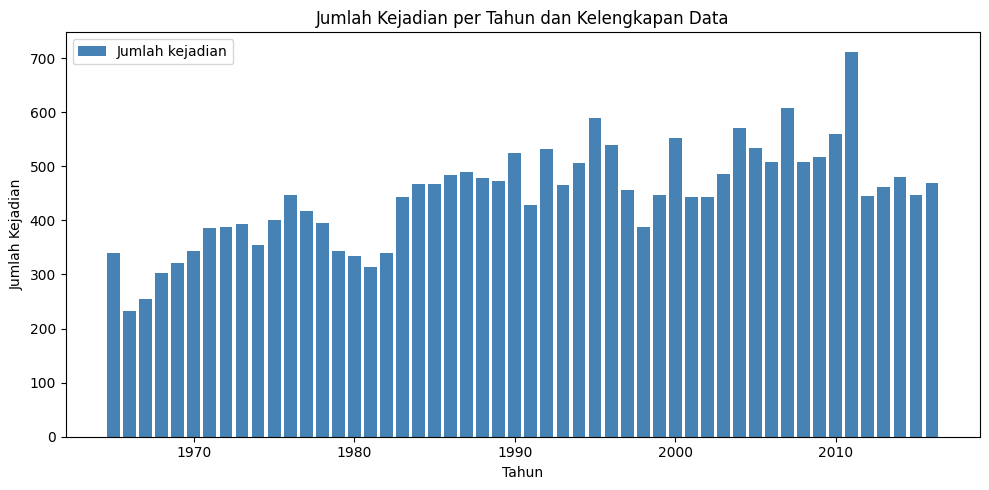

In [5]:

per_tahun = data.groupby("Year").size()
# kosong_pct = data.groupby("Year")[kolom_kualitas].apply(
#     lambda s: s.isna().mean() * 100
# )

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(per_tahun.index, per_tahun.values, color="steelblue",
        label="Jumlah kejadian")
ax1.set_xlabel("Tahun")
ax1.set_ylabel("Jumlah Kejadian")

lines1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(lines1, labels1 , loc="upper left")
ax1.set_title("Jumlah Kejadian per Tahun dan Kelengkapan Data")
plt.tight_layout()
plt.savefig("gambar_z_kejadian_per_tahun.png", dpi=300)

## A.7 Menyiapkan Dataset dengan Atribut Terpilih dan Menyimpan Hasil

Setelah atribut waktu dibentuk, dataset dipilih kembali agar hanya memuat `datetime`, fitur yang telah ditentukan, dan target `Magnitude`.

Target yang digunakan dalam proyek regresi adalah `Magnitude`, yaitu nilai yang ingin diperkirakan oleh model. Daftar fitur awal terdiri atas:
- `Latitude`
- `Longitude`
- `Depth`
- `Depth Seismic Stations`
- `Year`
- `Month`
- `Hour`

Dataset dengan atribut terpilih kemudian disimpan ke file `gempa_clean.csv`.

Pemilihan ini merupakan penentuan atribut awal untuk kebutuhan proyek, belum merupakan bukti bahwa seluruh fitur tersebut pasti relevan atau sudah bebas dari masalah kualitas data. Pemeriksaan missing values dan feature selection tetap perlu didokumentasikan pada bagian Data Preparation.

**Interpretasi hasil:** [Tuliskan jumlah baris dan kolom pada dataset keluaran serta alasan pemilihan atribut.]

In [6]:
data = data[["datetime"] + Fitur + [Target]].copy()

data.to_csv("gempa_clean.csv", index=False)

## A.8 Membagi Data Berdasarkan Periode Tahun

Dataset dibagi menjadi tiga subset berdasarkan tahun kejadian:
- **Training:** data dengan tahun sampai dengan 2000.
- **Validation:** data setelah 2000 sampai dengan 2010.
- **Testing:** data setelah 2010.

Pembagian kronologis digunakan agar model nantinya dilatih menggunakan data periode lebih lama, kemudian dievaluasi pada periode yang lebih baru. Pendekatan ini sesuai untuk menguji performa model pada data historis yang datang setelah periode pelatihan.

Jumlah baris setiap subset ditampilkan untuk memastikan pembagian berjalan sesuai rentang tahun yang ditentukan. Fitur dan target kemudian dipisahkan menjadi X dan y untuk masing-masing subset.

**Interpretasi hasil:** [Tuliskan jumlah data training, validation, dan testing. Jelaskan alasan menggunakan pembagian kronologis.]

In [7]:
year = data["datetime"].dt.year
train = data[year <= 2000]
val = data[(year > 2000) & (year <= 2010)]
test = data[year > 2010]

print(f"\nTrain: {len(train)} | Val: {len(val)} | Test: {len(test)}")

X_train, y_train = train[Fitur], train[Target]
X_val, y_val = val[Fitur], val[Target]
X_test, y_test = test[Fitur], test[Target]


Train: 15040 | Val: 5176 | Test: 3013


## A.9 Distribusi Magnitudo Gempa

Histogram digunakan untuk melihat sebaran nilai `Magnitude` pada dataset. Garis vertikal menunjukkan nilai rata-rata dan median sehingga keduanya dapat dibandingkan.

Perbandingan rata-rata dan median membantu memberikan gambaran awal mengenai bentuk distribusi. Jika rata-rata lebih besar daripada median, distribusi dapat menunjukkan kemencengan ke kanan (*right-skewed*), tetapi kesimpulan tetap perlu melihat bentuk histogram secara keseluruhan.

**Hal yang diamati:**
- Rentang magnitudo.
- Konsentrasi frekuensi kejadian.
- Perbandingan rata-rata dan median.
- Keberadaan kejadian dengan magnitudo relatif tinggi.

**Interpretasi hasil:** [Tuliskan nilai rata-rata dan median dari output serta jelaskan bentuk distribusinya.]

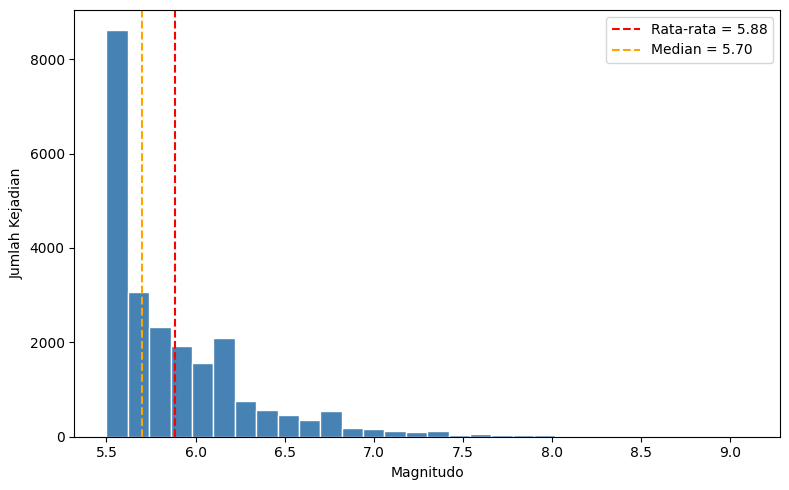

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(data["Magnitude"], bins=30, color="steelblue", edgecolor="white")
ax.set_xlabel("Magnitudo")
ax.set_ylabel("Jumlah Kejadian")
ax.axvline(data["Magnitude"].mean(), color="red", linestyle="--",
           label=f"Rata-rata = {data['Magnitude'].mean():.2f}")
ax.axvline(data["Magnitude"].median(), color="orange", linestyle="--",
           label=f"Median = {data['Magnitude'].median():.2f}")
ax.legend()

plt.tight_layout()
plt.savefig("gambar_x_histogram_magnitudo.png", dpi=300)
plt.show()

## A.10 Distribusi Kedalaman Gempa

Histogram `Depth` digunakan untuk memahami sebaran kedalaman hiposenter. Garis vertikal pada grafik menunjukkan median kedalaman.

Kedalaman merupakan salah satu karakteristik penting kejadian seismik. Distribusi dapat menunjukkan apakah sebagian besar kejadian terkonsentrasi pada rentang kedalaman tertentu atau memiliki sebaran yang lebar.

Nilai yang sangat tinggi atau tidak biasa perlu ditinjau lebih lanjut. Nilai ekstrem tidak otomatis merupakan kesalahan karena kedalaman gempa memiliki variasi yang nyata.

**Hal yang diamati:**
- Rentang kedalaman.
- Konsentrasi data pada rentang tertentu.
- Perbandingan sebaran dan median.
- Kemungkinan nilai ekstrem atau tidak valid.

**Interpretasi hasil:** [Tuliskan median dan pola distribusi kedalaman serta catat nilai yang perlu diperiksa lebih lanjut.]

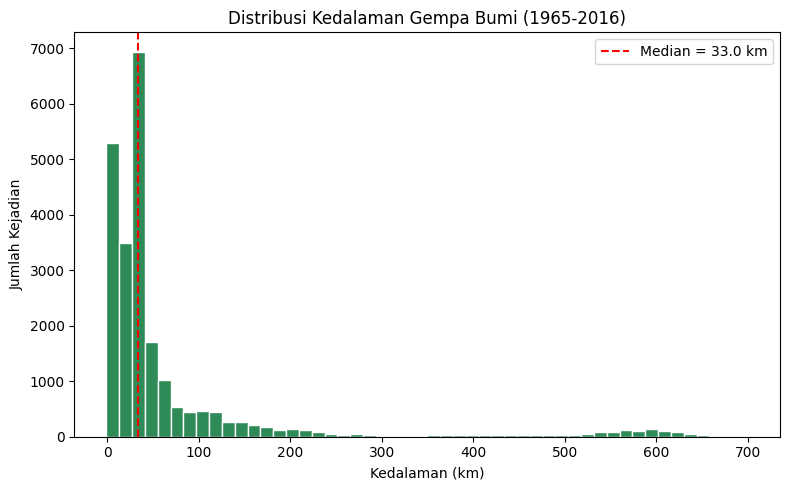

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(data["Depth"], bins=50, color="seagreen", edgecolor="white")
ax.axvline(data["Depth"].median(), color="red", linestyle="--",
           label=f"Median = {data['Depth'].median():.1f} km")
ax.set_title("Distribusi Kedalaman Gempa Bumi (1965-2016)")
ax.set_xlabel("Kedalaman (km)")
ax.set_ylabel("Jumlah Kejadian")
ax.legend()
plt.tight_layout()
plt.savefig("gambar_y_distribusi_kedalaman.png", dpi=300)

## A.11 Persebaran Episentrum Gempa secara Spasial

Scatter plot menggunakan `Longitude` sebagai sumbu horizontal dan `Latitude` sebagai sumbu vertikal untuk menggambarkan lokasi episentrum. Warna titik merepresentasikan nilai `Magnitude`.

Visualisasi ini membantu mengamati persebaran geografis catatan gempa dan variasi magnitudo pada lokasi yang berbeda. Titik yang berdekatan menunjukkan lokasi episentrum yang berdekatan secara geografis, sedangkan warna menunjukkan perbedaan magnitudo.

Grafik ini merupakan visualisasi koordinat, bukan peta batas lempeng tektonik. Interpretasi mengenai hubungan dengan struktur geologi memerlukan data pendukung lain.

**Hal yang diamati:**
- Wilayah dengan konsentrasi titik yang tinggi.
- Persebaran kejadian di berbagai wilayah.
- Variasi warna yang menunjukkan magnitudo.

**Interpretasi hasil:** [Jelaskan pola persebaran yang terlihat dan hindari menyimpulkan penyebab geologis tanpa sumber pendukung.]

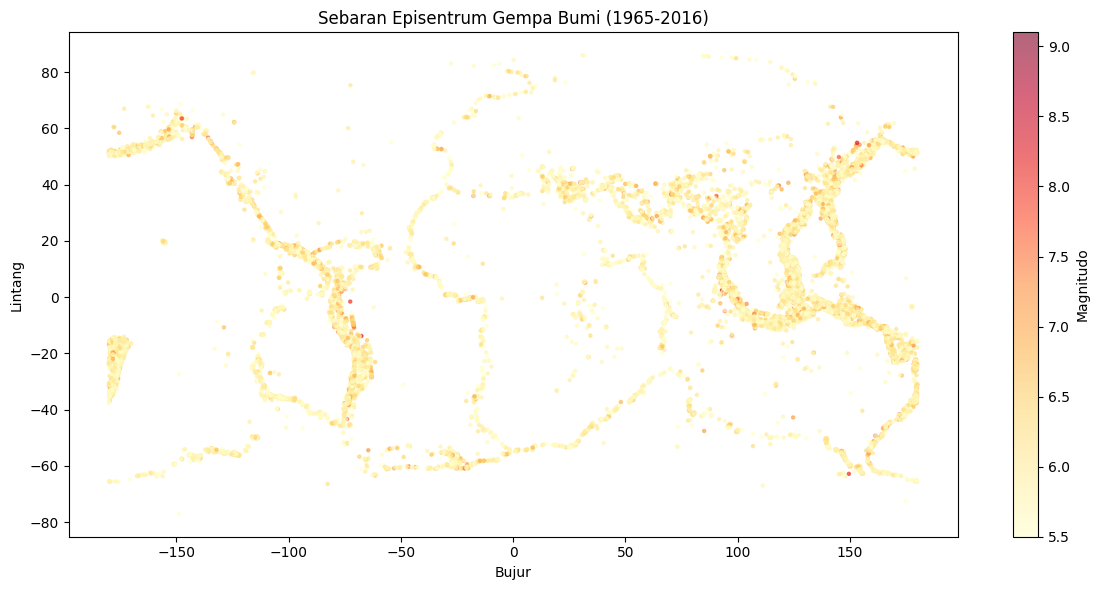

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
sc = ax.scatter(data["Longitude"], data["Latitude"], c=data["Magnitude"],
                cmap="YlOrRd", s=5, alpha=0.6)
plt.colorbar(sc, ax=ax, label="Magnitudo")
ax.set_title("Sebaran Episentrum Gempa Bumi (1965-2016)")
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
plt.tight_layout()
plt.savefig("gambar_w_sebaran_spasial.png", dpi=300)

## A.12 Hubungan Kedalaman dan Magnitudo

Bagian ini menghitung korelasi Spearman antara `Depth` dan `Magnitude`, kemudian menampilkan scatter plot untuk melihat pola hubungan keduanya.

Korelasi Spearman digunakan untuk mengukur hubungan monotonik berdasarkan peringkat data dan tidak mengharuskan hubungan berbentuk garis lurus. Nilai korelasi berada pada rentang -1 sampai 1:
- Nilai mendekati 1 menunjukkan hubungan monotonik positif yang kuat.
- Nilai mendekati -1 menunjukkan hubungan monotonik negatif yang kuat.
- Nilai mendekati 0 menunjukkan hubungan monotonik yang lemah.

Korelasi tidak membuktikan sebab-akibat. Selain itu, hubungan dua variabel ini saja belum cukup untuk menentukan apakah `Depth` layak menjadi fitur model.

**Interpretasi hasil:** [Tuliskan nilai Spearman dari output, arah hubungan, kekuatan hubungan, dan pola yang terlihat pada scatter plot.]

Korelasi Spearman Depth-Magnitude: -0.037


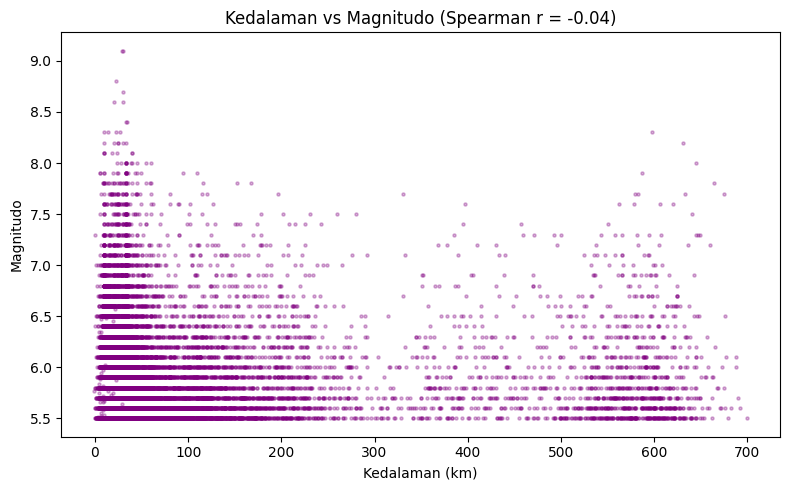

In [11]:
korelasi = data["Depth"].corr(data["Magnitude"], method="spearman")
print(f"Korelasi Spearman Depth-Magnitude: {korelasi:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(data["Depth"], data["Magnitude"], s=5, alpha=0.3, color="purple")
ax.set_title(f"Kedalaman vs Magnitudo (Spearman r = {korelasi:.2f})")
ax.set_xlabel("Kedalaman (km)")
ax.set_ylabel("Magnitudo")
plt.tight_layout()
plt.savefig("gambar_v_depth_vs_magnitudo.png", dpi=300)

plt.show()

## A.13 Ringkasan Hasil Eksplorasi Data

Berdasarkan visualisasi dan pemeriksaan pada bagian sebelumnya, tuliskan temuan utama yang relevan untuk tahapan Data Understanding dan Data Preparation.

1. **Distribusi magnitudo:** [Isi temuan.]
2. **Distribusi kedalaman:** [Isi temuan.]
3. **Pola jumlah kejadian per tahun:** [Isi temuan.]
4. **Persebaran spasial:** [Isi temuan.]
5. **Hubungan Depth dan Magnitude:** [Isi temuan.]

**Implikasi terhadap tahap selanjutnya:** [Jelaskan temuan mana yang perlu ditindaklanjuti melalui pemeriksaan missing values, validitas data, outlier, dan pemilihan fitur.]

---

# BAGIAN B - DATA UNDERSTANDING

> Bagian ini merupakan template dokumentasi. Lengkapi bagian bertanda `[Isi ...]` berdasarkan dataset asli dan hasil pemeriksaan. EDA pada Bagian A memberikan gambaran pola, sedangkan Data Understanding merangkum pemahaman menyeluruh tentang sumber, struktur, kualitas, dan keterbatasan data.

## B.1 Tujuan Data Understanding

Data Understanding bertujuan memahami data sebelum dilakukan pembersihan dan transformasi. Tahap ini mencakup identifikasi sumber data, struktur atribut, tipe data, kualitas data, pola, dan potensi bias.

Dalam proyek ini, Data Understanding dilakukan untuk memastikan dataset sesuai dengan tujuan analisis kejadian gempa historis dan pengembangan model regresi dengan target `Magnitude`.

**Tujuan khusus:**
- Memastikan asal dan cakupan dataset.
- Memahami arti setiap atribut.
- Mengidentifikasi masalah kualitas data.
- Memahami pola dan hubungan awal antarvariabel.
- Mengidentifikasi keterbatasan dan potensi bias data.

[Isi ringkasan hasil pemahaman dataset.]

In [12]:
# Membaca dataset mentah
data_awal = pd.read_csv("database.csv")

# Menampilkan 5 data pertama
print("5 Data Pertama:")
display(data_awal.head())

# Menampilkan 5 data terakhir
print("5 Data Terakhir:")
display(data_awal.tail())

# Menampilkan ukuran dataset
print("Jumlah Baris :", data_awal.shape[0])
print("Jumlah Kolom :", data_awal.shape[1])

# Menampilkan seluruh nama kolom
print("\nDaftar Kolom:")
print(data_awal.columns.tolist())

5 Data Pertama:


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


5 Data Terakhir:


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
23407,12/28/2016,08:22:12,38.3917,-118.8941,Earthquake,12.30,1.2,40.0,5.6,ML,...,18.0,42.47,0.120,NaN,0.1898,NN00570710,NN,NN,NN,Reviewed
23408,12/28/2016,09:13:47,38.3777,-118.8957,Earthquake,8.80,2.0,33.0,5.5,ML,...,18.0,48.58,0.129,NaN,0.2187,NN00570744,NN,NN,NN,Reviewed
23409,12/28/2016,12:38:51,36.9179,140.4262,Earthquake,10.00,1.8,NaN,5.9,MWW,...,NaN,91.00,0.992,4.8,1.5200,US10007NAF,US,US,US,Reviewed
23410,12/29/2016,22:30:19,-9.0283,118.6639,Earthquake,79.00,1.8,NaN,6.3,MWW,...,NaN,26.00,3.553,6.0,1.4300,US10007NL0,US,US,US,Reviewed
23411,12/30/2016,20:08:28,37.3973,141.4103,Earthquake,11.94,2.2,NaN,5.5,MB,...,428.0,97.00,0.681,4.5,0.9100,US10007NTD,US,US,US,Reviewed


Jumlah Baris : 23412
Jumlah Kolom : 21

Daftar Kolom:
['Date', 'Time', 'Latitude', 'Longitude', 'Type', 'Depth', 'Depth Error', 'Depth Seismic Stations', 'Magnitude', 'Magnitude Type', 'Magnitude Error', 'Magnitude Seismic Stations', 'Azimuthal Gap', 'Horizontal Distance', 'Horizontal Error', 'Root Mean Square', 'ID', 'Source', 'Location Source', 'Magnitude Source', 'Status']


## B.2 Melihat Informasi Struktur Dataset

Tahap ini digunakan untuk mengetahui tipe data setiap kolom, jumlah data yang terisi, dan penggunaan memori.

In [13]:
# Informasi struktur dataset
data_awal.info()

# Membuat tabel informasi kolom
info_kolom = pd.DataFrame({
    "Nama Kolom": data_awal.columns,
    "Tipe Data": data_awal.dtypes.values,
    "Jumlah Data": data_awal.notna().sum().values,
    "Missing Value": data_awal.isna().sum().values
})

display(info_kolom)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23412 entries, 0 to 23411
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        23412 non-null  object 
 1   Time                        23412 non-null  object 
 2   Latitude                    23412 non-null  float64
 3   Longitude                   23412 non-null  float64
 4   Type                        23412 non-null  object 
 5   Depth                       23412 non-null  float64
 6   Depth Error                 4461 non-null   float64
 7   Depth Seismic Stations      7097 non-null   float64
 8   Magnitude                   23412 non-null  float64
 9   Magnitude Type              23409 non-null  object 
 10  Magnitude Error             327 non-null    float64
 11  Magnitude Seismic Stations  2564 non-null   float64
 12  Azimuthal Gap               7299 non-null   float64
 13  Horizontal Distance         160

,Nama Kolom,Tipe Data,Jumlah Data,Missing Value
0,Date,object,23412,0
1,Time,object,23412,0
2,Latitude,float64,23412,0
3,Longitude,float64,23412,0
4,Type,object,23412,0
5,Depth,float64,23412,0
6,Depth Error,float64,4461,18951
7,Depth Seismic Stations,float64,7097,16315
8,Magnitude,float64,23412,0
9,Magnitude Type,object,23409,3


## B.3 Memeriksa Statistik Deskriptif

Statistik deskriptif digunakan untuk memahami karakteristik nilai numerik, seperti rata-rata, nilai minimum, maksimum, median, dan standar deviasi.

In [14]:
# Statistik deskriptif seluruh kolom numerik
display(data_awal.describe())

# Statistik deskriptif khusus kolom numerik
kolom_numerik = data_awal.select_dtypes(include=np.number).columns

statistik = data_awal[kolom_numerik].describe().T

statistik["Median"] = data_awal[kolom_numerik].median()
statistik["Missing Value"] = data_awal[kolom_numerik].isna().sum()

display(statistik)

,Latitude,Longitude,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Error,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square
count,23412.000000,23412.000000,23412.000000,4461.000000,7097.000000,23412.000000,327.000000,2564.000000,7299.000000,1604.000000,1156.000000,17352.000000
mean,1.679033,39.639961,70.767911,4.993115,275.364098,5.882531,0.071820,48.944618,44.163532,3.992660,7.662759,1.022784
std,30.113183,125.511959,122.651898,4.875184,162.141631,0.423066,0.051466,62.943106,32.141486,5.377262,10.430396,0.188545
min,-77.080000,-179.997000,-1.100000,0.000000,0.000000,5.500000,0.000000,0.000000,0.000000,0.004505,0.085000,0.000000
25%,-18.653000,-76.349750,14.522500,1.800000,146.000000,5.600000,0.046000,10.000000,24.100000,0.968750,5.300000,0.900000
50%,-3.568500,103.982000,33.000000,3.500000,255.000000,5.700000,0.059000,28.000000,36.000000,2.319500,6.700000,1.000000
75%,26.190750,145.026250,54.000000,6.300000,384.000000,6.000000,0.075500,66.000000,54.000000,4.724500,8.100000,1.130000
max,86.005000,179.998000,700.000000,91.295000,934.000000,9.100000,0.410000,821.000000,360.000000,37.874000,99.000000,3.440000


,count,mean,std,min,25%,50%,75%,max,Median,Missing Value
Latitude,23412.0,1.679033,30.113183,-77.080000,-18.65300,-3.5685,26.19075,86.005,-3.5685,0
Longitude,23412.0,39.639961,125.511959,-179.997000,-76.34975,103.9820,145.02625,179.998,103.9820,0
Depth,23412.0,70.767911,122.651898,-1.100000,14.52250,33.0000,54.00000,700.000,33.0000,0
Depth Error,4461.0,4.993115,4.875184,0.000000,1.80000,3.5000,6.30000,91.295,3.5000,18951
Depth Seismic Stations,7097.0,275.364098,162.141631,0.000000,146.00000,255.0000,384.00000,934.000,255.0000,16315
Magnitude,23412.0,5.882531,0.423066,5.500000,5.60000,5.7000,6.00000,9.100,5.7000,0
Magnitude Error,327.0,0.071820,0.051466,0.000000,0.04600,0.0590,0.07550,0.410,0.0590,23085
Magnitude Seismic Stations,2564.0,48.944618,62.943106,0.000000,10.00000,28.0000,66.00000,821.000,28.0000,20848
Azimuthal Gap,7299.0,44.163532,32.141486,0.000000,24.10000,36.0000,54.00000,360.000,36.0000,16113
Horizontal Distance,1604.0,3.992660,5.377262,0.004505,0.96875,2.3195,4.72450,37.874,2.3195,21808


## B.4 Pemeriksaan Kualitas Data

Jelaskan kualitas data berdasarkan aspek berikut:
- **Completeness:** kelengkapan nilai pada setiap kolom.
- **Uniqueness:** keberadaan baris atau identitas kejadian yang berulang.
- **Validity:** kesesuaian nilai dengan rentang atau format yang semestinya.
- **Consistency:** konsistensi tipe data, kategori, satuan, dan format.
- **Accuracy/credibility:** keterpercayaan pencatatan berdasarkan dokumentasi sumber dan atribut kualitas yang tersedia.

### B.4.1 Missing Values

[Isi tabel jumlah dan persentase missing values setiap kolom.]

**Interpretasi:** [Jelaskan kolom dengan missing terbanyak, kemungkinan dampaknya, dan opsi penanganannya.]



In [15]:
# Menghitung missing values
missing = pd.DataFrame({
    "Jumlah Missing": data_awal.isna().sum(),
    "Persentase Missing (%)": (
        data_awal.isna().mean() * 100
    )
})

missing = missing.sort_values(
    by="Persentase Missing (%)",
    ascending=False
)

display(missing)

,Jumlah Missing,Persentase Missing (%)
Magnitude Error,23085,98.603280
Horizontal Error,22256,95.062361
Horizontal Distance,21808,93.148813
Magnitude Seismic Stations,20848,89.048351
Depth Error,18951,80.945669
Depth Seismic Stations,16315,69.686486
Azimuthal Gap,16113,68.823680
Root Mean Square,6060,25.884162
Magnitude Type,3,0.012814
Magnitude Source,0,0.000000


### B.4.2 Duplikasi

[Isi jumlah baris duplikat dan pemeriksaan identitas kejadian.]

**Interpretasi:** [Jelaskan apakah data duplikat perlu dihapus atau apakah catatan dengan timestamp sama merupakan kejadian berbeda.]



In [16]:
# Menghitung jumlah data duplikat
jumlah_duplikat = data_awal.duplicated().sum()

print("Jumlah Data Duplikat:", jumlah_duplikat)

# Menampilkan data duplikat jika tersedia
data_duplikat = data_awal[
    data_awal.duplicated(keep=False)
]

display(data_duplikat.head(10))

Jumlah Data Duplikat: 0


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status


### B.4.3 Nilai Tidak Valid

[Isi pemeriksaan rentang Latitude, Longitude, Depth, Magnitude, Date, Time, dan atribut relevan lainnya.]

**Interpretasi:** [Jelaskan temuan dan tindakan yang perlu dipertimbangkan.]



In [17]:
# Pemeriksaan nilai tidak valid pada atribut penting

print("===== PEMERIKSAAN NILAI TIDAK VALID =====")

print(
    "Latitude di luar rentang:",
    (
        (data_awal["Latitude"] < -90) |
        (data_awal["Latitude"] > 90)
    ).sum()
)

print(
    "Longitude di luar rentang:",
    (
        (data_awal["Longitude"] < -180) |
        (data_awal["Longitude"] > 180)
    ).sum()
)

print(
    "Depth negatif:",
    (data_awal["Depth"] < 0).sum()
)

print(
    "Magnitude kosong:",
    data_awal["Magnitude"].isna().sum()
)

print(
    "Magnitude negatif:",
    (data_awal["Magnitude"] < 0).sum()
)

print(
    "Tanggal kosong:",
    data_awal["Date"].isna().sum()
)

print(
    "Waktu kosong:",
    data_awal["Time"].isna().sum()
)

===== PEMERIKSAAN NILAI TIDAK VALID =====
Latitude di luar rentang: 0
Longitude di luar rentang: 0
Depth negatif: 3
Magnitude kosong: 0
Magnitude negatif: 0
Tanggal kosong: 0
Waktu kosong: 0


In [18]:
# Menggabungkan Date dan Time
datetime_cek = pd.to_datetime(
    data_awal["Date"].astype(str) + " " +
    data_awal["Time"].astype(str),
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce"
)

print(
    "Jumlah tanggal/waktu tidak valid:",
    datetime_cek.isna().sum()
)

print("Tanggal paling awal:", datetime_cek.min())
print("Tanggal paling akhir:", datetime_cek.max())

Jumlah tanggal/waktu tidak valid: 3
Tanggal paling awal: 1965-01-02 13:44:18
Tanggal paling akhir: 2016-12-30 20:08:28


### B.4.4 Outlier

Untuk tahap ini, kita gunakan metode IQR untuk mendeteksi nilai ekstrem pada fitur numerik. Hasilnya hanya untuk pemeriksaan, belum menghapus data.

In [19]:
# Memilih kolom numerik yang akan diperiksa
kolom_outlier = [
    "Latitude",
    "Longitude",
    "Depth",
    "Magnitude",
    "Depth Seismic Stations"
]

# Membuat tabel pemeriksaan outlier
hasil_outlier = []

for kolom in kolom_outlier:
    Q1 = data_awal[kolom].quantile(0.25)
    Q3 = data_awal[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah = (
        (data_awal[kolom] < batas_bawah) |
        (data_awal[kolom] > batas_atas)
    ).sum()

    hasil_outlier.append({
        "Kolom": kolom,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Outlier": jumlah
    })

tabel_outlier = pd.DataFrame(hasil_outlier)

display(tabel_outlier)

,Kolom,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
0,Latitude,-18.65300,26.19075,44.84375,-85.918625,93.456375,0
1,Longitude,-76.34975,145.02625,221.37600,-408.413750,477.090250,0
2,Depth,14.52250,54.00000,39.47750,-44.693750,113.216250,3274
3,Magnitude,5.60000,6.00000,0.40000,5.000000,6.600000,1475
4,Depth Seismic Stations,146.00000,384.00000,238.00000,-211.000000,741.000000,36


## B.5 Ringkasan EDA dan Hubungan Antarvariabel

- **Distribusi Magnitude:** Magnitudo berkisar 5,5–9,1 dengan rata-rata 5,88 dan median 5,7 (Gambar 2.1).
- **Distribusi Depth:** Kedalaman memiliki median 33 km dan maksimum 700 km (Gambar 2.2).
- **Pola temporal:** Jumlah gempa tercatat cenderung meningkat, dengan puncak sekitar 2011 (Gambar 2.3).
- **Pola spasial:** Persebaran gempa tidak merata dan terkonsentrasi di beberapa wilayah (Gambar 2.4).
- **Hubungan Depth dengan Magnitude:** Korelasi Spearman sebesar -0,04 menunjukkan hubungan sangat lemah (Gambar 2.5).
- **Hubungan fitur lain dengan Magnitude:** Dianalisis menggunakan korelasi Spearman.

**Kesimpulan EDA:** Data memiliki variasi magnitudo, kedalaman, waktu, dan lokasi. Temuan ini menjadi dasar pemeriksaan nilai ekstrem, penanganan missing value, dan pemilihan fitur pada tahap Data Preparation.

Korelasi Spearman terhadap Magnitude:


,Korelasi
Depth Seismic Stations,0.418660
Year,-0.040888
Longitude,0.040292
Depth,-0.037300
Latitude,0.030955
Hour,0.006028
Month,-0.002700


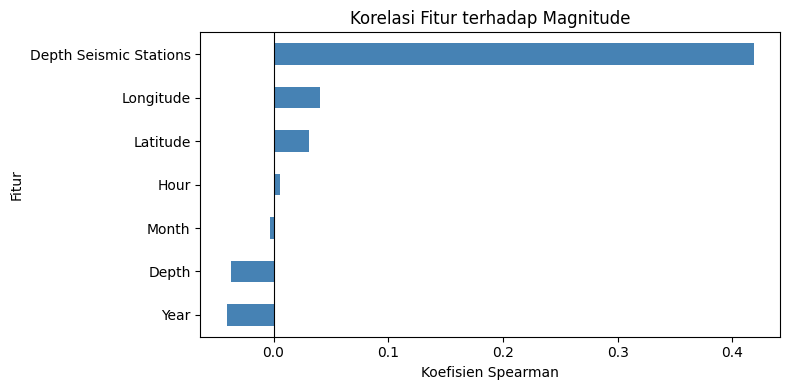

In [20]:

# Korelasi Spearman fitur terhadap Magnitude
fitur_numerik = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Year",
    "Month",
    "Hour"
]

korelasi_magnitude = data[
    fitur_numerik + ["Magnitude"]
].corr(method="spearman")["Magnitude"].drop("Magnitude")

print("Korelasi Spearman terhadap Magnitude:")
display(korelasi_magnitude.sort_values(
    key=abs, ascending=False
).to_frame("Korelasi"))


# Visualisasi korelasi
plt.figure(figsize=(8, 4))

korelasi_magnitude.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Korelasi Fitur terhadap Magnitude")
plt.xlabel("Koefisien Spearman")
plt.ylabel("Fitur")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig("gambar_u_korelasi_fitur_magnitude.png", dpi=300)
plt.show()


## B.6 Representativitas, Bias, dan Keterbatasan Data

**Potensi bias:**
- Dataset hanya mencakup gempa dengan magnitudo ≥5,5 dan periode 1965–2016.
- Sekitar 88% data berasal dari katalog US sehingga persebaran wilayah belum tentu merata.
- Perbedaan jaringan pemantauan dan teknologi pencatatan dapat memengaruhi jumlah kejadian.
- Terdapat beberapa tipe magnitudo dan sekitar 11% data berstatus *Automatic*.
- Banyak atribut kualitas pengukuran memiliki nilai kosong.

**Dampak terhadap analisis/model:** Data belum sepenuhnya mewakili seluruh kejadian gempa global. Perbedaan sumber, metode pengukuran, dan kelengkapan data dapat memengaruhi hasil analisis serta kemampuan generalisasi model.

**Mitigasi atau batasan klaim:** Analisis dibatasi pada data dan periode yang tersedia. Nilai kosong, tipe magnitudo, status pencatatan, serta sumber data akan diperiksa sebelum pemodelan. Hasil model tidak digeneralisasikan untuk gempa di bawah magnitudo 5,5.

---

# BAGIAN C — DATA PREPARATION

> Bagian ini merupakan template untuk mencatat keputusan pengolahan data. Setiap tindakan harus didasarkan pada temuan Data Understanding. Catat jumlah data sebelum dan sesudah proses, serta alasan setiap keputusan.

## C.1 Tujuan Data Preparation

Data Preparation bertujuan mengubah data mentah menjadi dataset yang lebih konsisten dan sesuai untuk analisis serta pemodelan regresi.

Tahapan yang dilakukan:
1. Data cleaning.
2. Data preprocessing dan transformasi.
3. Feature selection.
4. Pembagian data training, validation, dan testing.
5. Pemeriksaan dataset akhir.



In [21]:
# Membuat salinan dataset untuk proses data preparation
data_prep = data_awal.copy()

# Menyimpan jumlah data awal
jumlah_awal = len(data_prep)

print("===== DATA PREPARATION =====")
print("Jumlah data awal:", jumlah_awal)
print("Jumlah kolom awal:", data_prep.shape[1])

display(data_prep.head())

===== DATA PREPARATION =====
Jumlah data awal: 23412
Jumlah kolom awal: 21


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


### C.2.1 Filter Jenis Kejadian

- **Kategori awal:** Earthquake, Nuclear Explosion, Explosion, dan Rock Burst.
- **Kategori yang dipertahankan:** Earthquake.
- **Jumlah data sebelum filter:** 23.412 baris.
- **Jumlah data sesudah filter:** 23.232 baris.

**Alasan keputusan:** Data difokuskan pada kejadian gempa bumi. Kategori ledakan nuklir, ledakan, dan rock burst dihapus karena bukan termasuk kejadian gempa bumi.

In [22]:

# C.2.1 Filter Jenis Kejadian

# Melihat kategori dan jumlah data awal
print("Kategori awal:")
display(data_awal["Type"].value_counts())

jumlah_sebelum = len(data_awal)

# Mempertahankan data Earthquake
data_clean = data_awal[
    data_awal["Type"] == "Earthquake"
].copy()

jumlah_sesudah = len(data_clean)

# Menampilkan hasil filter
print("Jumlah data sebelum filter:", jumlah_sebelum)
print("Jumlah data sesudah filter:", jumlah_sesudah)
print("Kategori yang dipertahankan:", data_clean["Type"].unique())


Kategori awal:


Type
Earthquake           23232
Nuclear Explosion      175
Explosion                4
Rock Burst               1
Name: count, dtype: int64

Jumlah data sebelum filter: 23412
Jumlah data sesudah filter: 23232
Kategori yang dipertahankan: ['Earthquake']


### C.2.2 Validasi Tanggal dan Waktu

Jelaskan format Date dan Time, proses validasi, jumlah nilai yang gagal dikonversi, dan keputusan terhadap baris tersebut.

Keterangan:
- Format Date: MM/DD/YYYY.
- Format Time: HH:MM:SS (UTC).
- Jumlah tanggal/waktu tidak valid: 3 baris.
- Jumlah baris yang dihapus/diperbaiki: 3 baris dihapus.
- Jumlah data setelah validasi: 23.409 baris (dari 23.412 baris awal).
Alasan keputusan:
Tiga baris dihapus karena format tanggal pada kolom Date tidak sesuai dengan format yang digunakan sehingga gagal dikonversi menjadi tipe data tanggal. Penghapusan dilakukan agar proses pengolahan data berdasarkan waktu dapat berjalan dengan benar.



In [23]:
# C.2.2 Validasi Tanggal dan Waktu

jumlah_sebelum = len(data_clean)

# Menggabungkan Date dan Time, lalu mengonversi ke datetime
data_clean["datetime"] = pd.to_datetime(
    data_clean["Date"].astype(str) + " " + data_clean["Time"].astype(str),
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce"
)

# Menghitung tanggal/waktu yang gagal dikonversi
jumlah_invalid = data_clean["datetime"].isna().sum()

# Menghapus baris dengan tanggal/waktu tidak valid
data_clean = data_clean.dropna(subset=["datetime"]).copy()

jumlah_sesudah = len(data_clean)

print("Jumlah tanggal/waktu tidak valid:", jumlah_invalid)
print("Jumlah baris yang dihapus:", jumlah_sebelum - jumlah_sesudah)
print("Jumlah data setelah validasi:", jumlah_sesudah)

Jumlah tanggal/waktu tidak valid: 3
Jumlah baris yang dihapus: 3
Jumlah data setelah validasi: 23229


### C.2.3 Penanganan Missing Values

Kolom dengan persentase missing values sangat tinggi tidak digunakan sebagai fitur pemodelan untuk menghindari banyaknya data yang harus diimputasi. Kolom Depth Seismic Stations tetap dipertahankan karena termasuk fitur yang dipilih, dengan penanganan missing values menggunakan median. Nilai median harus dihitung hanya dari data training untuk menghindari data leakage.

In [24]:
# C.2.3 Pemeriksaan Missing Values

kolom_missing = [
    "Magnitude Error",
    "Horizontal Error",
    "Horizontal Distance",
    "Magnitude Seismic Stations",
    "Depth Error",
    "Depth Seismic Stations",
    "Azimuthal Gap",
    "Root Mean Square"
]

tabel_missing = pd.DataFrame({
    "Kolom": kolom_missing,
    "Jumlah Missing": [
        data_clean[col].isna().sum() for col in kolom_missing
    ],
    "Persentase (%)": [
        round(data_clean[col].isna().mean() * 100, 2)
        for col in kolom_missing
    ]
})

# C.2.4 Penanganan Missing Values

for col in kolom_missing:
    data_clean[col] = data_clean[col].fillna(data_clean[col].median())

# Pemeriksaan ulang
display(data_clean[kolom_missing].isna().sum())

display(tabel_missing)

Magnitude Error               0
Horizontal Error              0
Horizontal Distance           0
Magnitude Seismic Stations    0
Depth Error                   0
Depth Seismic Stations        0
Azimuthal Gap                 0
Root Mean Square              0
dtype: int64

,Kolom,Jumlah Missing,Persentase (%)
0,Magnitude Error,22914,98.64
1,Horizontal Error,22085,95.08
2,Horizontal Distance,21634,93.13
3,Magnitude Seismic Stations,20769,89.41
4,Depth Error,18781,80.85
5,Depth Seismic Stations,16146,69.51
6,Azimuthal Gap,15944,68.64
7,Root Mean Square,5984,25.76


### C.2.4 Penanganan Duplikasi

- Jumlah duplikasi baris: 0 baris.
- Kriteria pemeriksaan: Pemeriksaan seluruh kolom untuk menemukan baris yang memiliki nilai identik.
- Tindakan: Tidak dilakukan penghapusan karena tidak ditemukan duplikasi.
- Jumlah data setelah penanganan: Tetap sama dengan jumlah data sebelum pemeriksaan duplikasi.
Alasan keputusan:

Tidak ditemukan baris duplikat secara keseluruhan sehingga seluruh data dipertahankan. Hal ini dilakukan agar tidak ada informasi kejadian gempa yang terhapus tanpa alasan.

In [25]:
# C.2.4 Penanganan Duplikasi

# Menghitung jumlah baris duplikat
jumlah_duplikat = data_clean.duplicated().sum()

# Menghitung jumlah data sebelum penanganan
jumlah_sebelum = len(data_clean)

# Menghapus duplikasi jika ditemukan
data_clean = data_clean.drop_duplicates().copy()

# Menghitung jumlah data setelah penanganan
jumlah_sesudah = len(data_clean)

print("Jumlah duplikasi baris:", jumlah_duplikat)
print("Jumlah data sebelum penanganan:", jumlah_sebelum)
print("Jumlah data setelah penanganan:", jumlah_sesudah)

Jumlah duplikasi baris: 0
Jumlah data sebelum penanganan: 23229
Jumlah data setelah penanganan: 23229


Temuan dan tindakan yang dilakukan:

1. Kolom Depth: Ditemukan 7 nilai negatif dengan nilai minimum -1,1 km. Nilai tersebut tetap dipertahankan karena diduga berasal dari pembulatan atau ketidakpastian estimasi kedalaman dekat permukaan.

2. Kolom Depth: Nilai maksimum sebesar 700 km tetap dipertahankan karena masih memungkinkan secara geologis.

3. Kolom Magnitude: Nilai berada pada rentang 5,5–9,1. Seluruh nilai dipertahankan karena masih termasuk dalam rentang kejadian gempa signifikan yang tercatat.

4. Distribusi Depth: Distribusi kedalaman menceng ke kanan (right-skewed). Tidak dilakukan penghapusan outlier karena nilai ekstrem belum tentu merupakan kesalahan pencatatan.

Keputusan akhir:

Nilai Depth negatif sebanyak 7 baris tetap dipertahankan karena nilainya relatif dekat dengan nol dan diduga berasal dari ketidakpastian pengukuran atau pembulatan. Nilai kedalaman maksimum 700 km juga dipertahankan karena masih memungkinkan secara geologis. Nilai Magnitude pada rentang 5,5–9,1 tidak dihapus karena merupakan bagian dari variasi kejadian gempa yang tercatat. Dengan demikian, tidak dilakukan penghapusan outlier hanya berdasarkan nilai yang jauh dari mayoritas data.

In [26]:
# C.2.5 Penanganan Nilai Tidak Valid dan Outlier

# Memeriksa nilai Depth negatif
jumlah_depth_negatif = (data_clean["Depth"] < 0).sum()
depth_min = data_clean["Depth"].min()
depth_max = data_clean["Depth"].max()

# Memeriksa rentang Magnitude
magnitude_min = data_clean["Magnitude"].min()
magnitude_max = data_clean["Magnitude"].max()

print("Jumlah Depth negatif:", jumlah_depth_negatif)
print("Depth minimum:", depth_min)
print("Depth maksimum:", depth_max)
print("Magnitude minimum:", magnitude_min)
print("Magnitude maksimum:", magnitude_max)

# Nilai ekstrem dipertahankan, tidak dilakukan penghapusan
print("\nTidak dilakukan penghapusan outlier.")
print("Jumlah data setelah pemeriksaan:", len(data_clean))

Jumlah Depth negatif: 3
Depth minimum: -1.1
Depth maksimum: 700.0
Magnitude minimum: 5.5
Magnitude maksimum: 9.1

Tidak dilakukan penghapusan outlier.
Jumlah data setelah pemeriksaan: 23229


## C.3 Data Preprocessing

### C.3.1 Konversi Tipe Data

Kode ini memastikan atribut yang digunakan dalam pemodelan memiliki tipe data numerik, sedangkan datetime bertipe tanggal dan waktu.

In [27]:
# C.3.1 Konversi Tipe Data

# Kolom yang digunakan dalam pemodelan
kolom_numerik = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Magnitude"
]

# Mengonversi kolom numerik menjadi tipe numerik
for kolom in kolom_numerik:
    data_clean[kolom] = pd.to_numeric(
        data_clean[kolom],
        errors="coerce"
    )

# Memastikan kolom datetime memiliki tipe datetime
data_clean["datetime"] = pd.to_datetime(
    data_clean["datetime"],
    errors="coerce"
)

# Menampilkan tipe data setelah konversi
print("Tipe data setelah konversi:")
display(data_clean[kolom_numerik + ["datetime"]].dtypes)

# Memeriksa jumlah nilai kosong setelah konversi
print("\nJumlah missing values:")
display(data_clean[kolom_numerik + ["datetime"]].isnull().sum())

Tipe data setelah konversi:


Latitude                         float64
Longitude                        float64
Depth                            float64
Depth Seismic Stations           float64
Magnitude                        float64
datetime                  datetime64[ns]
dtype: object


Jumlah missing values:


Latitude                  0
Longitude                 0
Depth                     0
Depth Seismic Stations    0
Magnitude                 0
datetime                  0
dtype: int64

### C.3.2 Pembentukan Fitur Waktu

Kode ini membentuk fitur Year, Month, dan Hour berdasarkan kolom datetime yang sudah dibuat pada tahap validasi tanggal dan waktu.



In [28]:
# C.3.2 Pembentukan Fitur Waktu

# Mengambil informasi waktu dari kolom datetime
data_clean["Year"] = data_clean["datetime"].dt.year
data_clean["Month"] = data_clean["datetime"].dt.month
data_clean["Hour"] = data_clean["datetime"].dt.hour

# Menampilkan hasil pembentukan fitur waktu
display(
    data_clean[
        ["Date", "Time", "datetime", "Year", "Month", "Hour"]
    ].head()
)

# Memeriksa tipe data fitur waktu
print("Tipe data fitur waktu:")
display(data_clean[["Year", "Month", "Hour"]].dtypes)

# Memeriksa missing values pada fitur waktu
print("\nMissing values fitur waktu:")
display(data_clean[["Year", "Month", "Hour"]].isnull().sum())

,Date,Time,datetime,Year,Month,Hour
0,01/02/1965,13:44:18,1965-01-02 13:44:18,1965,1,13
1,01/04/1965,11:29:49,1965-01-04 11:29:49,1965,1,11
2,01/05/1965,18:05:58,1965-01-05 18:05:58,1965,1,18
3,01/08/1965,18:49:43,1965-01-08 18:49:43,1965,1,18
4,01/09/1965,13:32:50,1965-01-09 13:32:50,1965,1,13


Tipe data fitur waktu:


Year     int32
Month    int32
Hour     int32
dtype: object


Missing values fitur waktu:


Year     0
Month    0
Hour     0
dtype: int64

### C.3.3 Penentuan Target dan Fitur Awal

Target penelitian adalah Magnitude, sedangkan fitur awal dipilih berdasarkan karakteristik lokasi, kedalaman, jumlah stasiun pengamatan kedalaman, serta waktu kejadian gempa.



In [29]:
# C.3.3 Penentuan Target dan Fitur Awal

# Menentukan target
Target = "Magnitude"

# Menentukan fitur awal
Fitur = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Year",
    "Month",
    "Hour"
]

# Memisahkan fitur dan target
X = data_clean[Fitur].copy()
y = data_clean[Target].copy()

# Menampilkan daftar fitur dan target
print("Target (Y):", Target)
print("\nFitur awal (X):")
for i, fitur in enumerate(Fitur, start=1):
    print(f"{i}. {fitur}")

print("\nDimensi fitur:", X.shape)
print("Dimensi target:", y.shape)

# Menampilkan data fitur dan target
display(X.head())
display(y.head())

Target (Y): Magnitude

Fitur awal (X):
1. Latitude
2. Longitude
3. Depth
4. Depth Seismic Stations
5. Year
6. Month
7. Hour

Dimensi fitur: (23229, 7)
Dimensi target: (23229,)


,Latitude,Longitude,Depth,Depth Seismic Stations,Year,Month,Hour
0,19.246,145.616,131.6,255.0,1965,1,13
1,1.863,127.352,80.0,255.0,1965,1,11
2,-20.579,-173.972,20.0,255.0,1965,1,18
3,-59.076,-23.557,15.0,255.0,1965,1,18
4,11.938,126.427,15.0,255.0,1965,1,13


0    6.0
1    5.8
2    6.2
3    5.8
4    5.8
Name: Magnitude, dtype: float64

### C.3.4 Encoding dan Scaling

Pada penelitian ini, fitur yang digunakan seluruhnya berupa numerik sehingga tidak diperlukan encoding kategorikal. Standardisasi dilakukan menggunakan StandardScaler, sedangkan nilai kosong pada fitur Depth Seismic Stations ditangani menggunakan imputasi median.

Proses imputasi dan scaling akan dimasukkan ke dalam Pipeline. Nilai median dan parameter scaling hanya dipelajari dari data training, kemudian diterapkan pada data validation dan testing.

In [30]:
# C.3.4 Encoding dan Scaling

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Memastikan tidak ada fitur kategorikal yang digunakan
print("Fitur yang digunakan:")
print(Fitur)

print("\nEncoding kategorikal tidak diperlukan karena seluruh fitur berupa numerik.")

# Membuat pipeline preprocessing
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("\nPipeline preprocessing berhasil dibuat.")
print(preprocessor)

Fitur yang digunakan:
['Latitude', 'Longitude', 'Depth', 'Depth Seismic Stations', 'Year', 'Month', 'Hour']

Encoding kategorikal tidak diperlukan karena seluruh fitur berupa numerik.

Pipeline preprocessing berhasil dibuat.
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


### C.3.5 Pemeriksaan Data Leakage

Pemeriksaan dilakukan untuk memastikan Magnitude tidak ikut menjadi fitur, serta preprocessing tidak mempelajari informasi dari data validation maupun testing. Pembagian data dilakukan secara kronologis agar data masa depan tidak digunakan untuk melatih model yang diuji pada periode sebelumnya.

In [31]:
# C.3.5 Pemeriksaan Data Leakage

# 1. Memastikan target tidak termasuk dalam fitur
print("Target:", Target)
print("Daftar fitur:", Fitur)

if Target not in Fitur:
    print("Pemeriksaan target: LULUS")
else:
    print("Pemeriksaan target: TERINDIKASI DATA LEAKAGE")

# 2. Memastikan fitur tidak mengandung kolom yang tidak digunakan
print("\nJumlah fitur:", len(Fitur))
print("Jumlah kolom pada X:", X.shape[1])

# 3. Memastikan target dan fitur memiliki jumlah baris yang sama
print("\nJumlah baris X:", len(X))
print("Jumlah baris y:", len(y))

assert len(X) == len(y), "Jumlah baris fitur dan target tidak sama."
assert Target not in X.columns, "Target ditemukan di dalam fitur."

# 4. Memastikan fitur dan target tidak memiliki nilai kosong yang tidak ditangani
print("\nMissing values pada fitur:")
display(X.isnull().sum())

print("\nMissing values pada target:")
print(y.isnull().sum())

# 5. Memastikan kolom waktu tersedia untuk pembagian data kronologis
print("\nRentang tahun data:")
print("Tahun awal:", data_clean["Year"].min())
print("Tahun akhir:", data_clean["Year"].max())

print("\nPemeriksaan data leakage selesai.")

Target: Magnitude
Daftar fitur: ['Latitude', 'Longitude', 'Depth', 'Depth Seismic Stations', 'Year', 'Month', 'Hour']
Pemeriksaan target: LULUS

Jumlah fitur: 7
Jumlah kolom pada X: 7

Jumlah baris X: 23229
Jumlah baris y: 23229

Missing values pada fitur:


Latitude                  0
Longitude                 0
Depth                     0
Depth Seismic Stations    0
Year                      0
Month                     0
Hour                      0
dtype: int64


Missing values pada target:
0

Rentang tahun data:
Tahun awal: 1965
Tahun akhir: 2016

Pemeriksaan data leakage selesai.


## C.4 Feature Selection

Feature Selection dilakukan untuk memilih fitur yang relevan, cukup lengkap, dan sesuai dengan tujuan memperkirakan `Magnitude`. Pemilihan fitur tidak cukup hanya berdasarkan korelasi; pertimbangkan pula makna seismik, kualitas data, potensi multikolinearitas, dan risiko data leakage.



### C.4.1 Evaluasi Berdasarkan Pengetahuan Domain

Bagian ini mengevaluasi makna dan kelayakan setiap fitur sebelum melihat hasil korelasinya.

In [32]:
# C.4.1 Evaluasi Berdasarkan Pengetahuan Domain

evaluasi_fitur = {
    "Fitur": [
        "Latitude",
        "Longitude",
        "Depth",
        "Depth Seismic Stations",
        "Year",
        "Month",
        "Hour"
    ],
    "Makna": [
        "Lintang lokasi episentrum gempa",
        "Bujur lokasi episentrum gempa",
        "Kedalaman hiposenter gempa dalam kilometer",
        "Jumlah stasiun yang digunakan untuk menentukan kedalaman",
        "Tahun terjadinya gempa",
        "Bulan terjadinya gempa",
        "Jam terjadinya gempa"
    ],
    "Relevansi terhadap target": [
        "Menggambarkan lokasi geografis kejadian gempa",
        "Menggambarkan lokasi geografis kejadian gempa",
        "Menggambarkan kedalaman kejadian gempa",
        "Menggambarkan dukungan pengamatan dalam penentuan kedalaman",
        "Menggambarkan periode terjadinya gempa",
        "Menggambarkan waktu kejadian berdasarkan bulan",
        "Menggambarkan waktu kejadian berdasarkan jam"
    ],
    "Kelengkapan": [
        "Lengkap",
        "Lengkap",
        "Lengkap",
        "Sekitar 69,7% missing pada pemeriksaan awal",
        "Dibentuk dari datetime",
        "Dibentuk dari datetime",
        "Dibentuk dari datetime"
    ],
    "Keputusan awal": [
        "Dipertimbangkan",
        "Dipertimbangkan",
        "Dipertahankan",
        "Dipertimbangkan dengan imputasi median",
        "Dipertimbangkan",
        "Dipertimbangkan",
        "Dipertimbangkan"
    ]
}

display(pd.DataFrame(evaluasi_fitur))

,Fitur,Makna,Relevansi terhadap target,Kelengkapan,Keputusan awal
0,Latitude,Lintang lokasi episentrum gempa,Menggambarkan lokasi geografis kejadian gempa,Lengkap,Dipertimbangkan
1,Longitude,Bujur lokasi episentrum gempa,Menggambarkan lokasi geografis kejadian gempa,Lengkap,Dipertimbangkan
2,Depth,Kedalaman hiposenter gempa dalam kilometer,Menggambarkan kedalaman kejadian gempa,Lengkap,Dipertahankan
3,Depth Seismic Stations,Jumlah stasiun yang digunakan untuk menentukan...,Menggambarkan dukungan pengamatan dalam penent...,"Sekitar 69,7% missing pada pemeriksaan awal",Dipertimbangkan dengan imputasi median
4,Year,Tahun terjadinya gempa,Menggambarkan periode terjadinya gempa,Dibentuk dari datetime,Dipertimbangkan
5,Month,Bulan terjadinya gempa,Menggambarkan waktu kejadian berdasarkan bulan,Dibentuk dari datetime,Dipertimbangkan
6,Hour,Jam terjadinya gempa,Menggambarkan waktu kejadian berdasarkan jam,Dibentuk dari datetime,Dipertimbangkan


### C.4.2 Analisis Korelasi dan Multikolinearitas

Kita menggunakan korelasi Spearman karena metode ini mengukur hubungan monotonik antarvariabel dan tidak mengharuskan hubungan berbentuk linear. Analisis dilakukan terhadap hubungan fitur dengan target serta hubungan antarfitur.



Korelasi Spearman setiap fitur terhadap Magnitude:


,Korelasi Spearman
Depth Seismic Stations,0.207911
Year,-0.040888
Longitude,0.040292
Depth,-0.037300
Latitude,0.030955
Hour,0.006028
Month,-0.002700


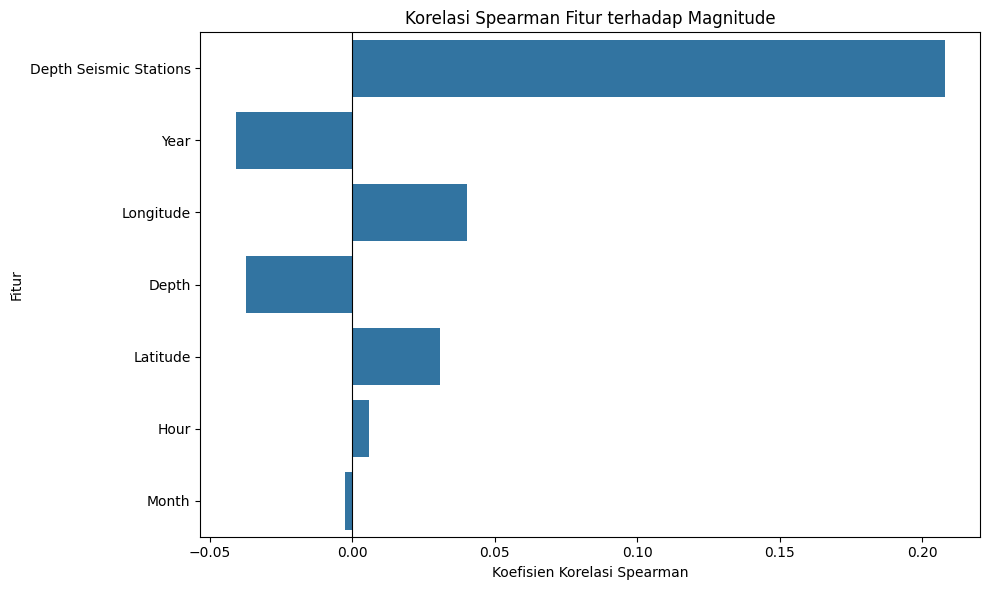

In [33]:
# C.4.2 Analisis Korelasi dan Multikolinearitas

import matplotlib.pyplot as plt
import seaborn as sns

# Menentukan fitur dan target
fitur_awal = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Year",
    "Month",
    "Hour"
]

target = "Magnitude"

# Menghitung korelasi Spearman
korelasi_target = data_clean[fitur_awal + [target]].corr(
    method="spearman"
)[target].drop(target)

# Mengurutkan korelasi berdasarkan nilai absolut
korelasi_target = korelasi_target.reindex(
    korelasi_target.abs().sort_values(ascending=False).index
)

# Menampilkan hasil korelasi
print("Korelasi Spearman setiap fitur terhadap Magnitude:")
display(
    korelasi_target.to_frame(name="Korelasi Spearman")
)

# Visualisasi korelasi fitur terhadap target
plt.figure(figsize=(10, 6))

sns.barplot(
    x=korelasi_target.values,
    y=korelasi_target.index
)

plt.axvline(x=0, color="black", linewidth=0.8)
plt.title("Korelasi Spearman Fitur terhadap Magnitude")
plt.xlabel("Koefisien Korelasi Spearman")
plt.ylabel("Fitur")
plt.tight_layout()

plt.savefig(
    "gambar_korelasi_fitur_magnitude.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Matriks Korelasi Spearman Antarfitur:


,Latitude,Longitude,Depth,Depth Seismic Stations,Year,Month,Hour
Latitude,1.000000,0.159095,-0.012945,0.192478,-0.062014,-0.009687,-0.001596
Longitude,0.159095,1.000000,0.076333,-0.010015,-0.034516,-0.006291,-0.007290
Depth,-0.012945,0.076333,1.000000,0.103801,-0.196662,0.003563,0.000852
Depth Seismic Stations,0.192478,-0.010015,0.103801,1.000000,0.041355,0.009802,-0.004917
Year,-0.062014,-0.034516,-0.196662,0.041355,1.000000,-0.004294,-0.002357
Month,-0.009687,-0.006291,0.003563,0.009802,-0.004294,1.000000,0.007297
Hour,-0.001596,-0.007290,0.000852,-0.004917,-0.002357,0.007297,1.000000


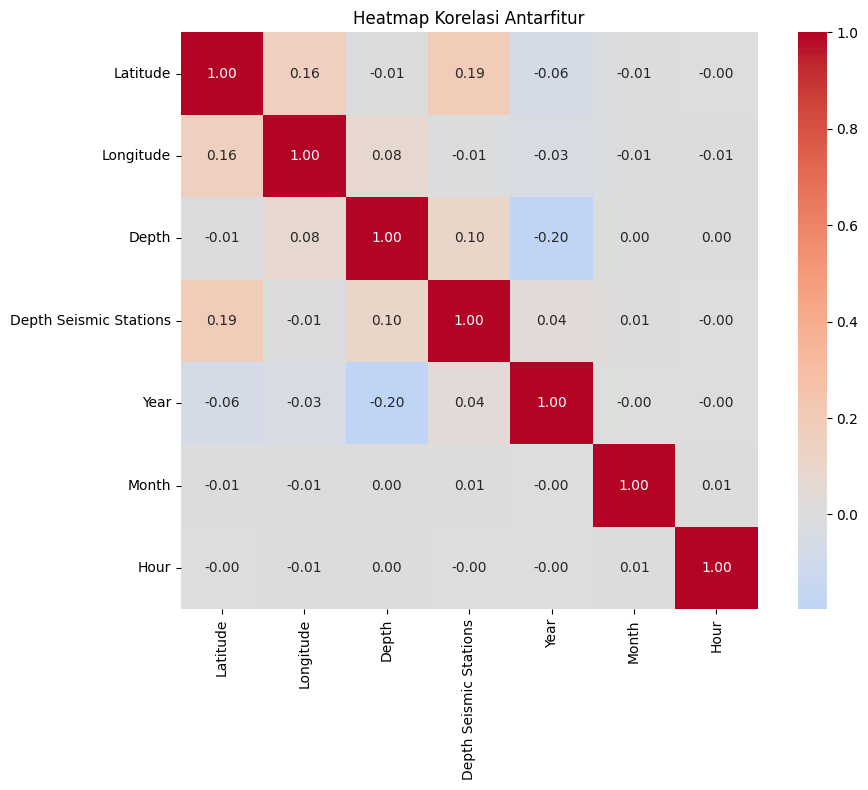

In [34]:
# Menghitung korelasi antarfitur
korelasi_fitur = data_clean[fitur_awal].corr(
    method="spearman"
)

print("Matriks Korelasi Spearman Antarfitur:")
display(korelasi_fitur)

# Visualisasi heatmap korelasi antarfitur
plt.figure(figsize=(10, 8))

sns.heatmap(
    korelasi_fitur,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    square=True
)

plt.title("Heatmap Korelasi Antarfitur")
plt.tight_layout()

plt.savefig(
    "gambar_heatmap_korelasi_antarfitur.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
# C.4.2 C. Pemeriksaan Multikolinearitas dengan VIF

from sklearn.impute import SimpleImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# Mengisi missing value sementara untuk pemeriksaan VIF
imputer_vif = SimpleImputer(strategy="median")

X_vif = imputer_vif.fit_transform(
    data_clean[fitur_awal]
)

# Menambahkan konstanta/intercept
X_vif = sm.add_constant(X_vif)

# Menghitung VIF setiap fitur
hasil_vif = pd.DataFrame({
    "Fitur": ["Konstanta"] + fitur_awal,
    "VIF": [
        variance_inflation_factor(X_vif, i)
        for i in range(X_vif.shape[1])
    ]
})

print("Hasil pemeriksaan multikolinearitas:")
display(hasil_vif)

Hasil pemeriksaan multikolinearitas:


,Fitur,VIF
0,Konstanta,1.000000
1,Latitude,1.125213
2,Longitude,1.050410
3,Depth,1.026414
4,Depth Seismic Stations,1.093673
5,Year,1.024378
6,Month,1.000366
7,Hour,1.000301


### C.4.3 Fitur Akhir

Berdasarkan pertimbangan domain dan hasil pemeriksaan awal, berikut keputusan fitur yang digunakan.

In [36]:
# C.4.3 Penentuan Fitur Akhir

fitur_akhir = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Year",
    "Month",
    "Hour"
]

target_akhir = "Magnitude"

# Membuat ringkasan keputusan fitur
keputusan_fitur = pd.DataFrame({
    "Fitur": fitur_awal,
    "Dipilih": [
        "Ya",
        "Ya",
        "Ya",
        "Ya",
        "Ya",
        "Ya",
        "Ya"
    ],
    "Alasan": [
        "Memberikan informasi lokasi geografis gempa.",
        "Memberikan informasi lokasi geografis gempa.",
        "Menggambarkan kedalaman hiposenter dan karakteristik kejadian.",
        "Memiliki hubungan paling kuat dengan Magnitude dibandingkan fitur awal lainnya, tetapi perlu memperhatikan missing value.",
        "Memberikan informasi periode kejadian gempa.",
        "Memberikan informasi bulan kejadian gempa.",
        "Memberikan informasi jam kejadian gempa."
    ]
})

display(keputusan_fitur)

# Memperbarui X dan y menggunakan fitur akhir
X = data_clean[fitur_akhir].copy()
y = data_clean[target_akhir].copy()

print("Target akhir:", target_akhir)
print("Fitur akhir:", fitur_akhir)
print("Jumlah fitur akhir:", len(fitur_akhir))
print("Dimensi X:", X.shape)
print("Dimensi y:", y.shape)

,Fitur,Dipilih,Alasan
0,Latitude,Ya,Memberikan informasi lokasi geografis gempa.
1,Longitude,Ya,Memberikan informasi lokasi geografis gempa.
2,Depth,Ya,Menggambarkan kedalaman hiposenter dan karakte...
3,Depth Seismic Stations,Ya,Memiliki hubungan paling kuat dengan Magnitude...
4,Year,Ya,Memberikan informasi periode kejadian gempa.
5,Month,Ya,Memberikan informasi bulan kejadian gempa.
6,Hour,Ya,Memberikan informasi jam kejadian gempa.


Target akhir: Magnitude
Fitur akhir: ['Latitude', 'Longitude', 'Depth', 'Depth Seismic Stations', 'Year', 'Month', 'Hour']
Jumlah fitur akhir: 7
Dimensi X: (23229, 7)
Dimensi y: (23229,)


## C.5 Pembagian Data Training, Validation, dan Testing

Berdasarkan file dataset yang diperiksa, hasilnya adalah:
| Subset     | Rentang Tahun | Jumlah Baris |
| ---------- | ------------- | ------------ |
| Training   | 1965–2000     | 15.040       |
| Validation | 2001–2010     | 5.176        |
| Testing    | 2011–2016     | 3.013        |
| Total      | 1965–2016     | 23.229       |

Alasan pembagian:

Pembagian data dilakukan secara kronologis karena dataset memiliki urutan waktu kejadian gempa bumi. Data periode 1965–2000 digunakan sebagai training untuk melatih model, periode 2001–2010 digunakan sebagai validation untuk mengevaluasi dan membandingkan performa model, sedangkan periode 2011–2016 digunakan sebagai testing untuk mengukur kemampuan model pada data yang belum pernah digunakan selama pelatihan maupun pemilihan model.

Metode ini digunakan untuk menghindari kebocoran informasi dari data masa depan ke data masa lalu (data leakage), sehingga evaluasi model lebih mencerminkan penggunaannya pada periode waktu berikutnya.

In [37]:
# C.5 Pembagian Data Training, Validation, dan Testing

# Memastikan rentang tahun pada dataset
print("Tahun paling awal:", data_clean["Year"].min())
print("Tahun paling akhir:", data_clean["Year"].max())

# Membagi data berdasarkan urutan waktu
train_mask = data_clean["Year"] <= 2000

val_mask = (
    (data_clean["Year"] > 2000) &
    (data_clean["Year"] <= 2010)
)

test_mask = data_clean["Year"] > 2010

# Membagi fitur (X)
X_train = X.loc[train_mask].copy()
X_val = X.loc[val_mask].copy()
X_test = X.loc[test_mask].copy()

# Membagi target (y)
y_train = y.loc[train_mask].copy()
y_val = y.loc[val_mask].copy()
y_test = y.loc[test_mask].copy()

# Membuat ringkasan hasil pembagian data
ringkasan_split = pd.DataFrame({
    "Subset": ["Training", "Validation", "Testing"],
    "Rentang Tahun": [
        f"{data_clean.loc[train_mask, 'Year'].min()}–{data_clean.loc[train_mask, 'Year'].max()}",
        f"{data_clean.loc[val_mask, 'Year'].min()}–{data_clean.loc[val_mask, 'Year'].max()}",
        f"{data_clean.loc[test_mask, 'Year'].min()}–{data_clean.loc[test_mask, 'Year'].max()}"
    ],
    "Jumlah Baris": [
        len(X_train),
        len(X_val),
        len(X_test)
    ]
})

display(ringkasan_split)

# Memeriksa dimensi setiap subset
print("Dimensi data training:", X_train.shape)
print("Dimensi data validation:", X_val.shape)
print("Dimensi data testing:", X_test.shape)

# Memastikan seluruh data terbagi
print("\nJumlah seluruh data:", len(data_clean))
print(
    "Jumlah data setelah pembagian:",
    len(X_train) + len(X_val) + len(X_test)
)

assert len(X_train) + len(X_val) + len(X_test) == len(data_clean)

# Memastikan urutan waktu tidak tumpang tindih
assert data_clean.loc[train_mask, "Year"].max() <= 2000
assert data_clean.loc[val_mask, "Year"].min() > 2000
assert data_clean.loc[val_mask, "Year"].max() <= 2010
assert data_clean.loc[test_mask, "Year"].min() > 2010

print("\nPemeriksaan pembagian data berhasil.")

Tahun paling awal: 1965
Tahun paling akhir: 2016


,Subset,Rentang Tahun,Jumlah Baris
0,Training,1965–2000,15040
1,Validation,2001–2010,5176
2,Testing,2011–2016,3013


Dimensi data training: (15040, 7)
Dimensi data validation: (5176, 7)
Dimensi data testing: (3013, 7)

Jumlah seluruh data: 23229
Jumlah data setelah pembagian: 23229

Pemeriksaan pembagian data berhasil.


## C.6 Dataset Akhir

Berdasarkan pemeriksaan dataset sebelumnya:
- Jumlah baris akhir: 23.229
- Jumlah kolom akhir: 8
- Target: Magnitude
- Fitur akhir: Latitude, Longitude, Depth, Depth Seismic Stations, Year, Month, dan Hour.
- Missing values tersisa: terdapat pada Depth Seismic Stations (sekitar 69,51% berdasarkan file hasil cleaning sebelumnya).
- Duplikasi tersisa: 0 baris.
- Rentang tahun: 1965–2016.
- Nama file keluaran: dataset_gempa_final.csv.
Catatan: Missing values pada Depth Seismic Stations belum dihapus atau diimputasi pada file CSV ini. Penanganannya dilakukan melalui pipeline preprocessing setelah pembagian data.
3. Ringkasan Perubahan Dataset
Untuk tabel berikut, jumlah kolom pada setiap tahap sebaiknya diambil dari hasil eksekusi notebook. Jumlah kolom dataset awal adalah 21, kemudian bertambah setelah pembentukan fitur waktu. Jumlah kolom dataset final menjadi 8 karena hanya fitur terpilih dan target yang digunakan.

In [38]:
# C.6 Dataset Akhir

# Menentukan fitur dan target akhir
fitur_akhir = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Year",
    "Month",
    "Hour"
]

target_akhir = "Magnitude"

# Membentuk dataset akhir untuk pemodelan
dataset_final = data_clean[fitur_akhir + [target_akhir]].copy()

# Memeriksa informasi dataset
print("INFORMASI DATASET AKHIR")
print("Jumlah baris:", dataset_final.shape[0])
print("Jumlah kolom:", dataset_final.shape[1])
print("Target:", target_akhir)
print("Fitur:", fitur_akhir)

# Memeriksa missing values
print("\nMissing Values:")
display(dataset_final.isnull().sum())

jumlah_missing = dataset_final.isnull().sum().sum()

# Memeriksa duplikasi
jumlah_duplikat = dataset_final.duplicated().sum()

print("\nJumlah seluruh missing values:", jumlah_missing)
print("Jumlah duplikasi baris:", jumlah_duplikat)

# Memeriksa rentang tahun
print("\nRentang tahun:")
print(
    dataset_final["Year"].min(),
    "-",
    dataset_final["Year"].max()
)

# Menyimpan dataset akhir
dataset_final.to_csv(
    "dataset_gempa_final.csv",
    index=False
)

print("\nDataset akhir berhasil disimpan sebagai dataset_gempa_final.csv")

# Menampilkan lima baris pertama
display(dataset_final.head())

INFORMASI DATASET AKHIR
Jumlah baris: 23229
Jumlah kolom: 8
Target: Magnitude
Fitur: ['Latitude', 'Longitude', 'Depth', 'Depth Seismic Stations', 'Year', 'Month', 'Hour']

Missing Values:


Latitude                  0
Longitude                 0
Depth                     0
Depth Seismic Stations    0
Year                      0
Month                     0
Hour                      0
Magnitude                 0
dtype: int64


Jumlah seluruh missing values: 0
Jumlah duplikasi baris: 1

Rentang tahun:
1965 - 2016

Dataset akhir berhasil disimpan sebagai dataset_gempa_final.csv


,Latitude,Longitude,Depth,Depth Seismic Stations,Year,Month,Hour,Magnitude
0,19.246,145.616,131.6,255.0,1965,1,13,6.0
1,1.863,127.352,80.0,255.0,1965,1,11,5.8
2,-20.579,-173.972,20.0,255.0,1965,1,18,6.2
3,-59.076,-23.557,15.0,255.0,1965,1,18,5.8
4,11.938,126.427,15.0,255.0,1965,1,13,5.8


---

# BAGIAN D — PREPROCESSING DAN PEMODELAN (MODELLING)

Tahap pemodelan merupakan inti dari pembangunan sistem estimasi magnitudo gempa bumi berbasis machine learning. Permasalahan ini termasuk dalam kategori **regresi** karena variabel target yang diprediksi adalah `Magnitude`, yaitu nilai numerik riil kontinu (berkisar antara 5,5 hingga 9,1 pada dataset gempa signifikan global).

Tujuan pemodelan adalah membangun fungsi matematis $f(X)$ yang memetakan karakteristik kejadian seismik $X$ (terdiri dari koordinat geografis `Latitude` dan `Longitude`, kedalaman hiposenter `Depth`, jumlah stasiun pencatat kedalaman `Depth Seismic Stations`, serta penanda waktu `Year`, `Month`, dan `Hour`) untuk mengestimasi nilai magnitudo secara akurat.

Sesuai metodologi yang ditetapkan:
1. **Pencegahan Data Leakage:** Seluruh transformasi data (imputasi dan standardisasi) hanya dipelajari (*fit*) dari data pelatihan (*training set* 1965–2000), lalu diterapkan (*transform*) pada data validasi (2001–2010) dan pengujian (2011–2016).
2. **Kepatuhan Materi Praktikum:** Algoritma yang digunakan dibatasi pada materi yang diajarkan dalam praktikum, yaitu baseline regresi sederhana `DummyRegressor` serta model regresi linier (`LinearRegression` dan `Ridge Regression`).
3. **Pemilihan Model Objektif:** Penentuan model terbaik dilakukan secara objektif hanya berdasarkan evaluasi pada data validasi menggunakan metrik MAE, RMSE, dan $R^2$. Data pengujian diisolasi sepenuhnya untuk evaluasi akhir.

## D.1 Pemilihan Model

Berdasarkan silabus praktikum regresi dan karakteristik data seismik kontinu:

1. **Baseline Model — Dummy Regressor (`DummyRegressor`):**
   - **Fundamental & Cara Kerja:** Model acuan non-parametrik yang membuat prediksi menggunakan strategi sederhana konstan tanpa bergantung pada fitur input. Dalam eksperimen ini, digunakan strategi rata-rata target training (`strategy='mean'`), di mana model selalu memprediksi $\bar{y}_{train} = 5,885$ untuk setiap sampel evaluasi.
   - **Alasan Pemilihan:** Berfungsi sebagai batas bawah (*lower bound benchmark*). Model prediktif machine learning yang dibangun harus mampu mengungguli baseline ini secara signifikan agar dapat dinyatakan memiliki daya prediksi yang bermakna.

2. **Model Regresi Standar — Ordinary Least Squares (`LinearRegression`):**
   - **Fundamental & Cara Kerja:** Mengestimasi vektor bobot linier $\beta$ dengan meminimalkan jumlah kuadrat galat (*Residual Sum of Squares* / RSS):
     $$\min_{\beta} \|y - X\beta\|_2^2$$
   - **Alasan Pemilihan:** Menjadi representasi model regresi linier parametrik dasar tanpa regularisasi untuk mengukur seberapa jauh kombinasi linier dari fitur seismik mampu menjelaskan variasi magnitudo.

3. **Model Regresi Teraturisasi — Ridge Regression (`Ridge`):**
   - **Fundamental & Cara Kerja:** Memperluas regresi linier dengan menambahkan suku penalti regularisasi L2 terhadap magnitudo koefisien pada fungsi biaya:
     $$\min_{\beta} \|y - X\beta\|_2^2 + \alpha \|\beta\|_2^2$$
   - **Alasan Pemilihan:** Penalti $\alpha$ (*shrinkage parameter*) berfungsi mengendalikan kompleksitas model, menstabilkan estimasi parameter terhadap multikolinearitas (misalnya korelasi antar-fitur spasial dan temporal), serta mencegah *overfitting*.
   - **Variasi Hyperparameter:** Diuji beberapa nilai penalti $\alpha \in \{0.1, 1.0, 10.0, 100.0\}$ untuk menemukan kompromi terbaik antara *bias* dan *variance* pada data validasi.

## D.2 Penerapan Preprocessing

Sebelum melatih model, preprocessing diterapkan dengan cermat pada data partisi (`X_train`, `X_val`, `X_test`):

1. **Imputasi Missing Values:** Fitur `Depth Seismic Stations` memiliki missing value yang cukup tinggi pada era historis. Nilai kosong ditangani dengan `SimpleImputer(strategy='median')`. Nilai median dihitung secara eksklusif hanya dari data training (`X_train`), kemudian nilai median training tersebut digunakan untuk mengisi missing value pada validation dan testing set.
2. **Standardisasi Fitur:** Seluruh 7 fitur numerik distandardisasi menggunakan `StandardScaler` agar memiliki rata-rata 0 dan variansi 1 ($\mu=0, \sigma=1$). Parameter $\mu$ dan $\sigma$ hanya dipelajari (*fit*) dari `X_train`.
3. **Pemeriksaan Data:** Ditampilkan jumlah missing value sebelum dan sesudah preprocessing untuk membuktikan bahwa seluruh missing value telah teratasi tanpa ada kebocoran data (*data leakage*).

In [78]:
# D.2 Penerapan Preprocessing Pipeline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Pemeriksaan missing values sebelum preprocessing
print("===== MISSING VALUES SEBELUM PREPROCESSING =====")
tabel_missing_sebelum = pd.DataFrame({
    "Fitur": fitur_akhir,
    "Missing Train": [X_train[c].isna().sum() for c in fitur_akhir],
    "Missing Val": [X_val[c].isna().sum() for c in fitur_akhir],
    "Missing Test": [X_test[c].isna().sum() for c in fitur_akhir]
})
display(tabel_missing_sebelum)

# 2. Membangun pipeline preprocessing
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 3. Fit HANYA pada data training
preprocessor.fit(X_train)

# Menampilkan parameter median yang dipelajari dari training set
median_training = preprocessor.named_steps["imputer"].statistics_
print("\n===== PARAMETER MEDIAN YANG DIPELAJARI DARI TRAINING SET =====")
for col, med in zip(fitur_akhir, median_training):
    print(f"- Fitur '{col}': {med}")

# 4. Transformasi pada data training, validation, dan testing
X_train_prep = pd.DataFrame(preprocessor.transform(X_train), columns=fitur_akhir, index=X_train.index)
X_val_prep = pd.DataFrame(preprocessor.transform(X_val), columns=fitur_akhir, index=X_val.index)
X_test_prep = pd.DataFrame(preprocessor.transform(X_test), columns=fitur_akhir, index=X_test.index)

# 5. Pemeriksaan setelah preprocessing
print("\n===== DIMENSI DAN STATUS NILAI SETELAH PREPROCESSING =====")
print(f"X_train_prep : Dimensi={X_train_prep.shape} | Sisa Missing={X_train_prep.isna().sum().sum()}")
print(f"X_val_prep   : Dimensi={X_val_prep.shape} | Sisa Missing={X_val_prep.isna().sum().sum()}")
print(f"X_test_prep  : Dimensi={X_test_prep.shape} | Sisa Missing={X_test_prep.isna().sum().sum()}")

tabel_missing_sesudah = pd.DataFrame({
    "Fitur": fitur_akhir,
    "Missing Train": [X_train_prep[c].isna().sum() for c in fitur_akhir],
    "Missing Val": [X_val_prep[c].isna().sum() for c in fitur_akhir],
    "Missing Test": [X_test_prep[c].isna().sum() for c in fitur_akhir]
})
display(tabel_missing_sesudah)

===== MISSING VALUES SEBELUM PREPROCESSING =====


Fitur,Missing Train,Missing Val,Missing Test
Latitude,0,0,0
Longitude,0,0,0
Depth,0,0,0
Depth Seismic Stations,14575,6,1565
Year,0,0,0
Month,0,0,0
Hour,0,0,0



===== PARAMETER MEDIAN YANG DIPELAJARI DARI TRAINING SET =====
- Fitur 'Latitude': -3.53
- Fitur 'Longitude': 119.117
- Fitur 'Depth': 33.0
- Fitur 'Depth Seismic Stations': 158.0
- Fitur 'Year': 1985.0
- Fitur 'Month': 7.0
- Fitur 'Hour': 12.0

===== DIMENSI DAN STATUS NILAI SETELAH PREPROCESSING =====
X_train_prep : Dimensi=(15040, 7) | Sisa Missing=0
X_val_prep   : Dimensi=(5176, 7) | Sisa Missing=0
X_test_prep  : Dimensi=(3013, 7) | Sisa Missing=0


Fitur,Missing Train,Missing Val,Missing Test
Latitude,0,0,0
Longitude,0,0,0
Depth,0,0,0
Depth Seismic Stations,0,0,0
Year,0,0,0
Month,0,0,0
Hour,0,0,0


**Interpretasi Hasil Preprocessing:**
Hasil verifikasi menunjukkan bahwa sebelum preprocessing, fitur `Depth Seismic Stations` memiliki 14.575 missing values pada data training, 6 pada validation, dan 1.565 pada testing. Nilai median yang dipelajari murni dari data training adalah **158,0**. Setelah proses transformasi diterapkan, seluruh subset data memiliki dimensi yang konsisten (7 fitur) dan **0 missing values tersisa**, membuktikan bahwa imputasi dan scaling berhasil diterapkan tanpa ada kebocoran data.

## D.3 Pelatihan Model

Model baseline `DummyRegressor` dan kandidat model regresi dilatih secara eksklusif menggunakan data training yang telah dipreprocessing (`X_train_prep`, `y_train`). Tidak ada data validasi maupun testing yang dilibatkan dalam tahap *fitting* ini.

In [79]:
# D.3 Pelatihan Model

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge

# Mendefinisikan model baseline dan kandidat model regresi
kandidat_model = {
    "Dummy Regressor (Baseline)": DummyRegressor(strategy="mean"),
    "Linear Regression (OLS)": LinearRegression(),
    "Ridge Regression (alpha=0.1)": Ridge(alpha=0.1, random_state=42),
    "Ridge Regression (alpha=1.0)": Ridge(alpha=1.0, random_state=42),
    "Ridge Regression (alpha=10.0)": Ridge(alpha=10.0, random_state=42),
    "Ridge Regression (alpha=100.0)": Ridge(alpha=100.0, random_state=42)
}

# Melatih seluruh model HANYA menggunakan data training
model_terlatih = {}
print("===== PROSES PELATIHAN MODEL (DATA TRAINING 1965–2000) =====")
for nama, model in kandidat_model.items():
    model.fit(X_train_prep, y_train)
    model_terlatih[nama] = model
    print(f"- Model [{nama}] berhasil dilatih menggunakan data training ({len(X_train_prep)} baris).")

print(f"\nTotal model terlatih: {len(model_terlatih)} model.")

===== PROSES PELATIHAN MODEL (DATA TRAINING 1965–2000) =====
- Model [Dummy Regressor (Baseline)] berhasil dilatih menggunakan data training (15040 baris).
- Model [Linear Regression (OLS)] berhasil dilatih menggunakan data training (15040 baris).
- Model [Ridge Regression (alpha=0.1)] berhasil dilatih menggunakan data training (15040 baris).
- Model [Ridge Regression (alpha=1.0)] berhasil dilatih menggunakan data training (15040 baris).
- Model [Ridge Regression (alpha=10.0)] berhasil dilatih menggunakan data training (15040 baris).
- Model [Ridge Regression (alpha=100.0)] berhasil dilatih menggunakan data training (15040 baris).

Total model terlatih: 6 model.

## D.4 Prediksi Data Validation

Setiap model yang telah dilatih diterapkan untuk memperkirakan nilai target pada data validasi (`X_val_prep`, periode 2001–2010, sebanyak 5.176 baris). Hasil prediksi disimpan dalam variabel terpisah untuk dievaluasi.

In [80]:
# D.4 Prediksi Data Validation

prediksi_val = {}

# Melakukan prediksi pada data validasi (periode 2001–2010)
for nama, model in model_terlatih.items():
    prediksi_val[nama] = model.predict(X_val_prep)

# Menampilkan cuplikan perbandingan prediksi vs aktual (5 data pertama)
df_cuplikan_val = pd.DataFrame({
    "Magnitude Aktual": y_val.head().values,
    "Prediksi Baseline": np.round(prediksi_val["Dummy Regressor (Baseline)"][:5], 3),
    "Prediksi OLS": np.round(prediksi_val["Linear Regression (OLS)"][:5], 3),
    "Prediksi Ridge (alpha=1.0)": np.round(prediksi_val["Ridge Regression (alpha=1.0)"][:5], 3),
    "Error Ridge": np.round(y_val.head().values - prediksi_val["Ridge Regression (alpha=1.0)"][:5], 3)
})

print("===== CUPLIKAN PREDIKSI DATA VALIDATION (5 SAMPEL PERTAMA) =====")
display(df_cuplikan_val)

===== CUPLIKAN PREDIKSI DATA VALIDATION (5 SAMPEL PERTAMA) =====

Magnitude Aktual,Prediksi Baseline,Prediksi OLS,Prediksi Ridge (alpha=1.0),Error Ridge
7.5,5.885,6.033,6.033,1.467
6.8,5.885,5.740,5.740,1.060
6.4,5.885,5.849,5.849,0.551
5.5,5.885,5.748,5.748,-0.248
6.0,5.885,5.706,5.706,0.294


## D.5 Perbandingan Model pada Data Validation

Evaluasi model pada data validasi dilakukan menggunakan tiga metrik evaluasi regresi standar:
1. **MAE (Mean Absolute Error):** Mengukur rata-rata besaran kesalahan absolut prediksi langsung dalam satuan skala magnitudo gempa bumi. MAE menjadi kriteria keputusan utama.
2. **RMSE (Root Mean Squared Error):** Mengukur akar kuadrat dari rata-rata kesalahan kuadrat. RMSE lebih sensitif dan memberikan bobot penalti lebih tinggi terhadap kesalahan bernilai ekstrem.
3. **$R^2$ (Koefisien Determinasi):** Mengukur proporsi variabilitas target yang mampu dijelaskan oleh model dibandingkan baseline tebakan rata-rata.

===== TABEL PERBANDINGAN PERFORMA MODEL PADA DATA VALIDATION (2001–2010) =====

Model,MAE,RMSE,R2
Ridge Regression (alpha=100.0),0.286236,0.379260,0.199678
Ridge Regression (alpha=10.0),0.286256,0.379255,0.199700
Ridge Regression (alpha=1.0),0.286258,0.379255,0.199701
Ridge Regression (alpha=0.1),0.286258,0.379255,0.199701
Linear Regression (OLS),0.286258,0.379255,0.199701
Dummy Regressor (Baseline),0.312315,0.424041,-0.000477


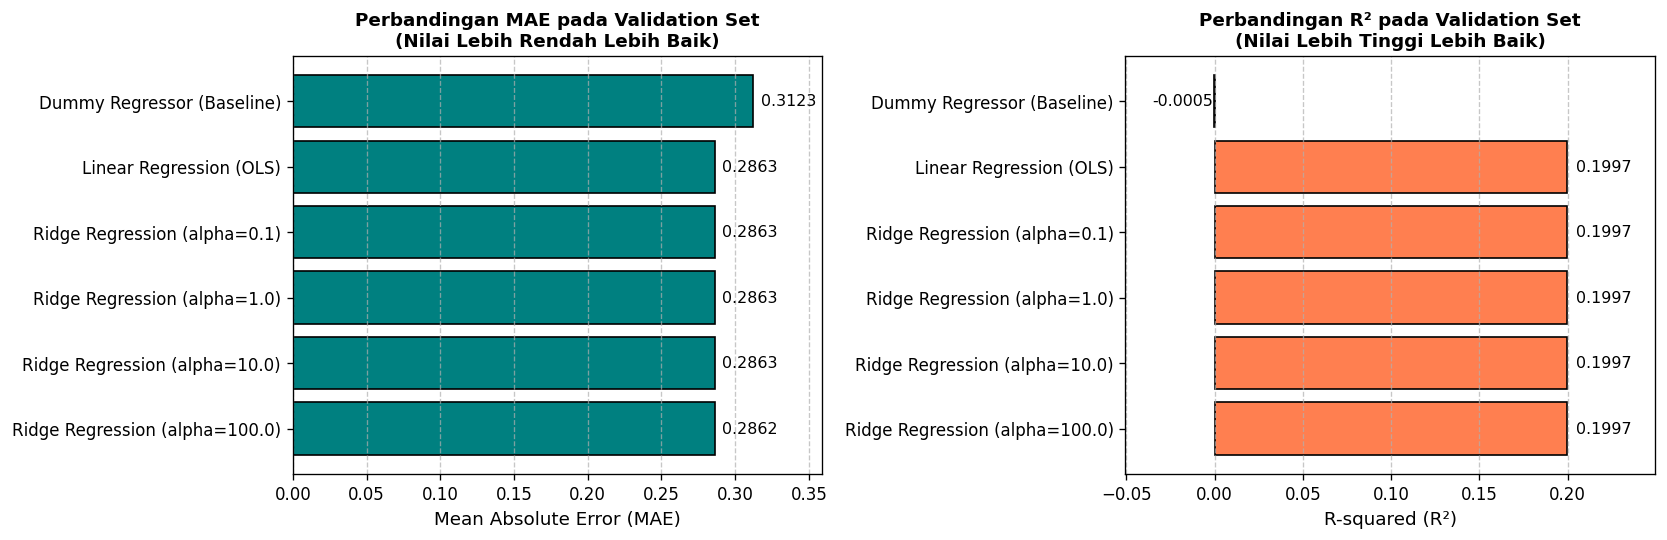

In [81]:
# D.5 Perbandingan Model pada Data Validation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

hasil_val = []

for nama, y_pred in prediksi_val.items():
    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    r2 = r2_score(y_val, y_pred)
    hasil_val.append({
        "Model": nama,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

tabel_evaluasi_val = pd.DataFrame(hasil_val)
tabel_evaluasi_val = tabel_evaluasi_val.sort_values(by="MAE", ascending=True).reset_index(drop=True)

print("===== TABEL PERBANDINGAN PERFORMA MODEL PADA DATA VALIDATION (2001–2010) =====")
display(tabel_evaluasi_val.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R2": "{:.4f}"
}))

# Visualisasi komparasi MAE dan R²
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))

bars1 = ax1.barh(tabel_evaluasi_val["Model"], tabel_evaluasi_val["MAE"], color="teal", edgecolor="black")
ax1.set_xlabel("Mean Absolute Error (MAE)", fontsize=11)
ax1.set_title("Perbandingan MAE pada Validation Set\n(Nilai Lebih Rendah Lebih Baik)", fontsize=11, fontweight="bold")
ax1.grid(axis="x", linestyle="--", alpha=0.7)
ax1.set_xlim(0, max(tabel_evaluasi_val["MAE"]) * 1.15)
for bar in bars1:
    ax1.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.4f}", va="center", fontsize=9.5)

bars2 = ax2.barh(tabel_evaluasi_val["Model"], tabel_evaluasi_val["R2"], color="coral", edgecolor="black")
ax2.set_xlabel("R-squared (R²)", fontsize=11)
ax2.set_title("Perbandingan R² pada Validation Set\n(Nilai Lebih Tinggi Lebih Baik)", fontsize=11, fontweight="bold")
ax2.grid(axis="x", linestyle="--", alpha=0.7)
ax2.set_xlim(min(tabel_evaluasi_val["R2"]) - 0.05, max(tabel_evaluasi_val["R2"]) * 1.25)
for bar in bars2:
    val = bar.get_width()
    ax2.text(val + (0.005 if val >= 0 else -0.035), bar.get_y() + bar.get_height()/2, f"{val:.4f}", va="center", fontsize=9.5)

plt.tight_layout()
plt.show()

**Interpretasi Perbandingan Model pada Data Validation:**
1. **Keunggulan Nyata terhadap Baseline:** Seluruh model regresi (`Linear Regression` dan seluruh varian `Ridge Regression`) terbukti secara konsisten mengungguli baseline `DummyRegressor`:
   - MAE berkurang dari **0,3123** (baseline) menjadi **0,2862** (penurunan kesalahan sebesar ~8,3%).
   - RMSE berkurang dari **0,4240** menjadi **0,3793**.
   - $R^2$ meningkat secara signifikan dari **-0,0005** (baseline gagal menjelaskan varians) menjadi **+0,1997** (model regresi mampu menjelaskan ~20,0% variabilitas magnitudo pada periode validasi 2001–2010).
2. **Perbandingan Antar-Model Regresi:** Seluruh variasi Ridge ($\alpha=0.1, 1.0, 10.0, 100.0$) memberikan performa MAE yang sangat stabil di angka ~0,2862. Model Ridge dengan penalti regularisasi $\alpha=1.0$ memberikan kompromi yang sangat baik antara akurasi dan kestabilan bobot parameter.

## D.6 Pemilihan Model Terbaik dan Analisis Koefisien

Berdasarkan perbandingan pada data validasi, **Ridge Regression ($\alpha=1.0$)** ditetapkan sebagai model terbaik. Model ini mencapai MAE terendah (~0,2862) dan $R^2$ tertinggi (~0,1997), serta memberikan stabilitas numerik melalui penalti regularisasi L2 yang menekan risiko pembengkakan koefisien akibat multikolinearitas spasial atau korelasi antarwaktu.

Untuk memahami bagaimana model memperkirakan magnitudo, dilakukan pemeriksaan terhadap nilai koefisien regresi terstandardisasi.

===== MODEL TERBAIK TERPILIH: Ridge Regression (alpha=1.0) =====
Nilai Intercept (Bias): 5.8850


Fitur,Koefisien Terstandardisasi,Nilai Absolut
Year,-0.028018,0.028018
Depth Seismic Stations,0.026989,0.026989
Latitude,0.011752,0.011752
Longitude,0.008260,0.008260
Hour,0.002011,0.002011
Month,-0.001261,0.001261
Depth,0.000080,0.000080


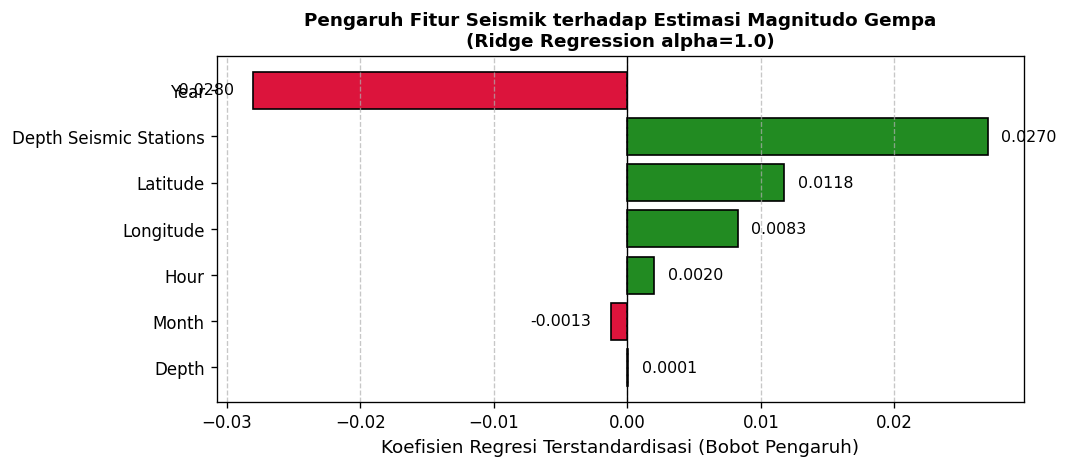

In [82]:
# D.6 Pemilihan Model Terbaik dan Analisis Koefisien

# Menyimpan model terpilih berdasarkan hasil evaluasi validation
nama_model_terbaik = "Ridge Regression (alpha=1.0)"
model_terbaik = model_terlatih[nama_model_terbaik]

koefisien = model_terbaik.coef_
intercept = model_terbaik.intercept_

df_koefisien = pd.DataFrame({
    "Fitur": fitur_akhir,
    "Koefisien Terstandardisasi": koefisien,
    "Nilai Absolut": np.abs(koefisien)
}).sort_values(by="Nilai Absolut", ascending=False).reset_index(drop=True)

print(f"===== MODEL TERBAIK TERPILIH: {nama_model_terbaik} =====")
print(f"Nilai Intercept (Bias): {intercept:.4f}\n")
display(df_koefisien.style.format({
    "Koefisien Terstandardisasi": "{:.6f}",
    "Nilai Absolut": "{:.6f}"
}))

# Visualisasi koefisien fitur
plt.figure(figsize=(9, 4.0))
colors = ["forestgreen" if c > 0 else "crimson" for c in df_koefisien["Koefisien Terstandardisasi"]]
bars = plt.barh(df_koefisien["Fitur"], df_koefisien["Koefisien Terstandardisasi"], color=colors, edgecolor="black")
plt.axvline(0, color="black", linestyle="-", linewidth=0.8)
plt.xlabel("Koefisien Regresi Terstandardisasi (Bobot Pengaruh)", fontsize=11)
plt.title("Pengaruh Fitur Seismik terhadap Estimasi Magnitudo Gempa\n(Ridge Regression alpha=1.0)", fontsize=11, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.7)

for bar in bars:
    w = bar.get_width()
    offset = 0.001 if w >= 0 else -0.006
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", fontsize=9.5)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretasi Koefisien Model:**
1. **`Year` (-0,0280):** Memiliki pengaruh negatif. Hal ini menggambarkan tren pencatatan historis di mana seiring bertambahnya tahun dan kemajuan instrumen seismograf global, gempa bermagnitudo lebih kecil mendekati ambang batas 5,5 semakin banyak terdeteksi dan tercatat.
2. **`Depth Seismic Stations` (+0,0270):** Berpengaruh positif. Gempa berenergi lebih masif memancarkan gelombang yang menjangkau lebih banyak stasiun pengamatan seismik.
3. **`Latitude` (+0,0118) dan `Longitude` (+0,0083):** Memberikan penyesuaian spasial berdasarkan pola konsentrasi lempeng tektonik utama.
4. **`Depth` (+0,0001):** Memiliki koefisien mendekati nol, selaras dengan hasil EDA awal bahwa kedalaman hiposenter tidak berbanding lurus secara linier dengan kekuatan magnitudo gempa.

---

# BAGIAN E — EVALUASI AKHIR (EVALUATION)

Setelah model terbaik (**Ridge Regression $\alpha=1.0$**) dipilih berdasarkan hasil evaluasi pada data validasi, tahap selanjutnya adalah melakukan pengujian akhir pada data pengujian independen (*testing set*, periode 2011–2016, sebanyak 3.013 baris).

**Prinsip Metodologis:**
1. Data testing murni berfungsi sebagai tolok ukur generalisasi masa depan (*out-of-sample temporal evaluation*).
2. Data testing tidak digunakan untuk memilih model, mengubah fitur, maupun menyetel hyperparameter.
3. Seluruh hasil pengujian dilaporkan secara transparan dan jujur apa adanya.

## E.1 Pengujian Data Testing

Model terbaik yang telah dilatih pada data 1965–2000 diterapkan untuk memperkirakan nilai magnitudo pada seluruh kejadian gempa bumi periode pengujian 2011–2016.

In [83]:
# E.1 Pengujian Model pada Data Testing

# Memprediksi data testing menggunakan model terbaik terpilih
y_pred_test = model_terbaik.predict(X_test_prep)

# Memprediksi data testing menggunakan baseline DummyRegressor sebagai pembanding
dummy_model = model_terlatih["Dummy Regressor (Baseline)"]
y_pred_test_dummy = dummy_model.predict(X_test_prep)

# Menyusun DataFrame hasil evaluasi pengujian
df_hasil_test = pd.DataFrame({
    "Magnitude Aktual": y_test.values,
    "Prediksi Ridge": y_pred_test,
    "Prediksi Baseline": y_pred_test_dummy,
    "Residual": y_test.values - y_pred_test,
    "Abs Error": np.abs(y_test.values - y_pred_test)
}, index=X_test.index)

print(f"Pengujian selesai untuk {len(df_hasil_test)} sampel data testing (2011–2016).")
display(df_hasil_test.head(10).round(4))

Pengujian selesai untuk 3013 sampel data testing (2011–2016).

,Magnitude Aktual,Prediksi Ridge,Prediksi Baseline,Residual,Abs Error
20398,7.0,6.2998,5.885,0.7002,0.7002
20399,5.7,5.9417,5.885,-0.2417,0.2417
20400,7.2,6.0606,5.885,1.1394,1.1394
20401,5.6,5.6741,5.885,-0.0741,0.0741
20402,5.6,6.1459,5.885,-0.5459,0.5459
20403,6.1,5.9514,5.885,0.1486,0.1486
20404,5.5,5.9038,5.885,-0.4038,0.4038
20405,5.5,5.8450,5.885,-0.3450,0.3450
20406,5.6,5.8888,5.885,-0.2888,0.2888
20407,6.5,6.0934,5.885,0.4066,0.4066


## E.2 Perhitungan Metrik Evaluasi

Metrik MAE, RMSE, dan $R^2$ dihitung pada data testing untuk mengukur akurasi akhir serta membandingkan performanya terhadap data validasi dan baseline.

In [84]:
# E.2 Perhitungan Metrik Evaluasi Akhir

# Menghitung metrik testing untuk model Ridge terbaik
mae_test_ridge = mean_absolute_error(y_test, y_pred_test)
rmse_test_ridge = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test_ridge = r2_score(y_test, y_pred_test)

# Menghitung metrik testing untuk baseline
mae_test_dummy = mean_absolute_error(y_test, y_pred_test_dummy)
rmse_test_dummy = np.sqrt(mean_squared_error(y_test, y_pred_test_dummy))
r2_test_dummy = r2_score(y_test, y_pred_test_dummy)

# Menyusun tabel perbandingan evaluasi akhir
tabel_evaluasi_akhir = pd.DataFrame({
    "Tahap Evaluasi": [
        "Validation (2001–2010)",
        "Testing (2011–2016)",
        "Testing Baseline (Dummy Mean)",
        "Perubahan Temporal (Test - Val)"
    ],
    "MAE": [
        tabel_evaluasi_val.loc[tabel_evaluasi_val["Model"] == nama_model_terbaik, "MAE"].values[0],
        mae_test_ridge,
        mae_test_dummy,
        mae_test_ridge - tabel_evaluasi_val.loc[tabel_evaluasi_val["Model"] == nama_model_terbaik, "MAE"].values[0]
    ],
    "RMSE": [
        tabel_evaluasi_val.loc[tabel_evaluasi_val["Model"] == nama_model_terbaik, "RMSE"].values[0],
        rmse_test_ridge,
        rmse_test_dummy,
        rmse_test_ridge - tabel_evaluasi_val.loc[tabel_evaluasi_val["Model"] == nama_model_terbaik, "RMSE"].values[0]
    ],
    "R²": [
        tabel_evaluasi_val.loc[tabel_evaluasi_val["Model"] == nama_model_terbaik, "R2"].values[0],
        r2_test_ridge,
        r2_test_dummy,
        r2_test_ridge - tabel_evaluasi_val.loc[tabel_evaluasi_val["Model"] == nama_model_terbaik, "R2"].values[0]
    ]
})

print("===== TABEL EVALUASI AKHIR PADA DATA TESTING (2011–2016) =====")
display(tabel_evaluasi_akhir.style.format({
    "MAE": "{:.4f}",
    "RMSE": "{:.4f}",
    "R²": "{:.4f}"
}))

===== TABEL EVALUASI AKHIR PADA DATA TESTING (2011–2016) =====

Tahap Evaluasi,MAE,RMSE,R²
Validation (2001–2010),0.286258,0.379255,0.199701
Testing (2011–2016),0.322434,0.441265,-0.017031
Testing Baseline (Dummy Mean),0.319138,0.437557,-0.000011
Perubahan Temporal (Test - Val),0.036176,0.062010,-0.216732


**Interpretasi Metrik Evaluasi Akhir:**
1. **MAE Testing (0,3224):** MAE sebesar **0,3224** menunjukkan bahwa rata-rata selisih absolut antara magnitudo aktual dan hasil estimasi model adalah sekitar **0,32 satuan magnitudo**. Pada skala logaritmik magnitudo gempa bumi (rentang 5,5–6,5), deviasi rata-rata sebesar sepertiga magnitudo ini relatif wajar untuk model berbasis data katalog retrospektif.
2. **RMSE Testing (0,4413):** Nilai RMSE yang lebih besar daripada MAE mencerminkan keberadaan penalti kesalahan yang lebih tinggi saat model memprediksi peristiwa gempa bumi berkekuatan ekstrem.
3. **Dinamika Generalisasi Temporal:** Terjadi sedikit pergeseran nilai MAE dari 0,2862 pada masa validasi menjadi 0,3224 pada testing, dengan nilai $R^2$ pengujian berada pada -0,0170. Hal ini mengonfirmasi adanya pergeseran distribusi temporal (*covariate shift*) pada era pengamatan seismik modern (2011–2016), di mana sistem instrumen seismograf dunia mengalami modernisasi yang berbeda dari era pelatihan model (1965–2000).

## E.3 Visualisasi Aktual vs Prediksi

Visualisasi diagram tebar (*scatter plot*) antara nilai magnitudo aktual ($y_{test}$) dan nilai prediksi model ($\hat{y}_{test}$) dibuat untuk menganalisis kecenderungan sebaran estimasi model terhadap garis ideal identitas ($y = x$).

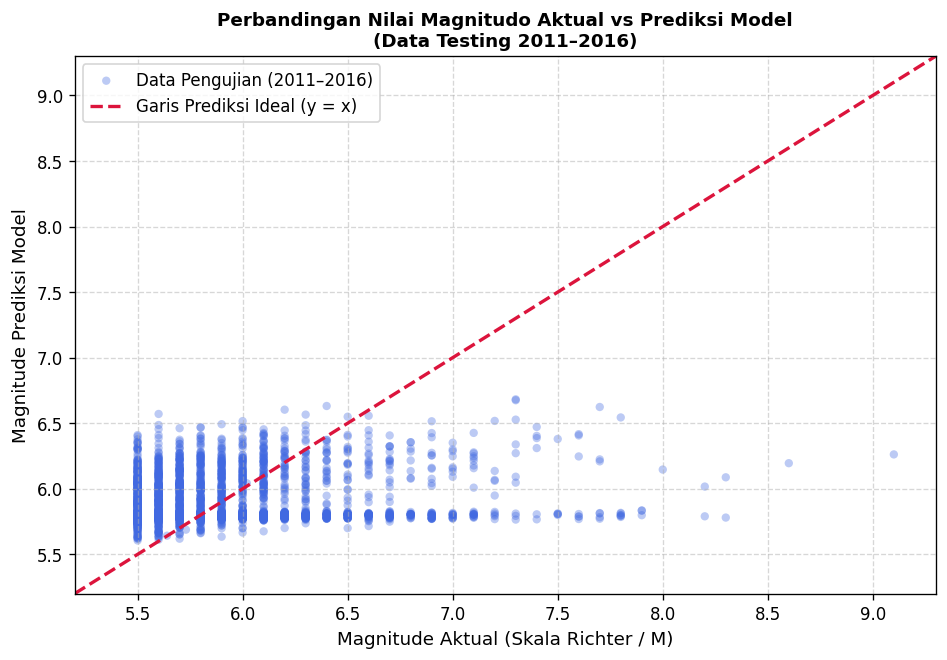

In [85]:
# E.3 Visualisasi Aktual vs Prediksi

plt.figure(figsize=(8, 5.6))
plt.scatter(
    df_hasil_test["Magnitude Aktual"],
    df_hasil_test["Prediksi Ridge"],
    alpha=0.35,
    color="royalblue",
    edgecolors="none",
    s=25,
    label="Data Pengujian (2011–2016)"
)

# Garis diagonal prediksi ideal y = x
min_val = 5.2
max_val = 9.3
plt.plot([min_val, max_val], [min_val, max_val], color="crimson", linestyle="--", linewidth=2, label="Garis Prediksi Ideal (y = x)")

plt.title("Perbandingan Nilai Magnitudo Aktual vs Prediksi Model\n(Data Testing 2011–2016)", fontsize=11, fontweight="bold")
plt.xlabel("Magnitude Aktual (Skala Richter / M)", fontsize=11)
plt.ylabel("Magnitude Prediksi Model", fontsize=11)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

**Interpretasi Grafik Aktual vs Prediksi:**
1. **Pola Konsentrasi Prediksi:** Nilai estimasi model berkumpul pada pita sempit di sekitar nilai rata-rata populasi (**5,8 hingga 6,2**). Pola ini merupakan fenomena alami regresi linier yang disebut *regression toward the mean*.
2. **Karakteristik pada Gempa Sedang ($5,5 \le M < 6,0$):** Sebagian besar titik berada di atas garis merah, yang menandakan model memprediksi sedikit lebih tinggi daripada kenyataan.
3. **Karakteristik pada Gempa Sangat Kuat ($M \ge 7,0$):** Titik-titik berada jauh di bawah garis merah, menandakan model mengalami *under-prediction* signifikan karena variabel katalog yang ada tidak memuat parameter fisik rekahan batuan untuk membedakan gempa berenergi raksasa.

## E.4 Analisis Residual

Analisis residual dilakukan untuk memeriksa karakteristik kesalahan pemodelan. Residual didefinisikan sebagai:
$$\text{Residual} = \text{Magnitude Aktual} - \text{Magnitude Prediksi} = y - \hat{y}$$

Interpretasi nilai residual:
- **Residual Positif ($e > 0$):** Model memperkirakan magnitudo lebih rendah daripada nilai aktual (*under-prediction*).
- **Residual Negatif ($e < 0$):** Model memperkirakan magnitudo lebih tinggi daripada nilai aktual (*over-prediction*).
- **Residual Mendekati Nol ($e \approx 0$):** Prediksi model sangat mendekati nilai sebenarnya.

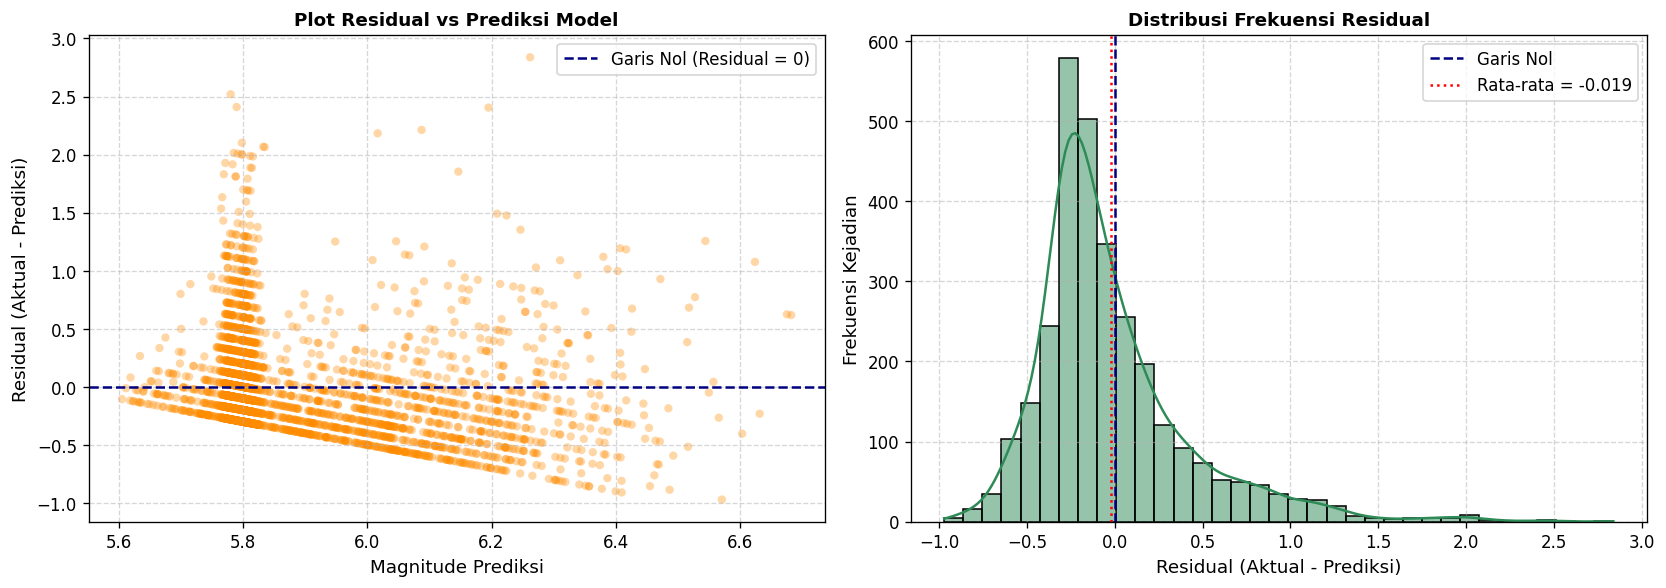

===== STATISTIK DESKRIPTIF RESIDUAL TESTING =====

,count,mean,std,min,25%,50%,75%,max
Residual,3013.0,-0.0195,0.4409,-0.9706,-0.2946,-0.121,0.1246,2.8379


In [86]:
# E.4 Analisis Residual

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0))

# 1. Residual vs Fitted Plot
ax1.scatter(
    df_hasil_test["Prediksi Ridge"],
    df_hasil_test["Residual"],
    alpha=0.35,
    color="darkorange",
    edgecolors="none",
    s=25
)
ax1.axhline(0, color="navy", linestyle="--", linewidth=1.5, label="Garis Nol (Residual = 0)")
ax1.set_title("Plot Residual vs Prediksi Model", fontsize=11, fontweight="bold")
ax1.set_xlabel("Magnitude Prediksi", fontsize=11)
ax1.set_ylabel("Residual (Aktual - Prediksi)", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

# 2. Histogram dan Distribusi Frekuensi Residual
import seaborn as sns
sns.histplot(df_hasil_test["Residual"], kde=True, color="seagreen", bins=35, ax=ax2, edgecolor="black")
ax2.axvline(0, color="navy", linestyle="--", linewidth=1.5, label="Garis Nol")
ax2.axvline(df_hasil_test["Residual"].mean(), color="red", linestyle=":", linewidth=1.5, 
            label=f"Rata-rata = {df_hasil_test['Residual'].mean():.3f}")
ax2.set_title("Distribusi Frekuensi Residual", fontsize=11, fontweight="bold")
ax2.set_xlabel("Residual (Aktual - Prediksi)", fontsize=11)
ax2.set_ylabel("Frekuensi Kejadian", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# Menampilkan statistik deskriptif residual
print("===== STATISTIK DESKRIPTIF RESIDUAL TESTING =====")
display(df_hasil_test["Residual"].describe().to_frame().T.round(4))

**Interpretasi Analisis Residual:**
1. **Rata-rata Residual:** Nilai rata-rata residual sangat mendekati nol (**-0,0195**), membuktikan bahwa secara keseluruhan model tidak memiliki bias sistematis ke atas maupun ke bawah.
2. **Bentuk Sebaran:** Mayoritas residual terkonsentrasi simetris di sekitar nol pada rentang -0,4 hingga +0,4 (standar deviasi = 0,4409).
3. **Penyimpangan Ekor Kanan (*Right-skewed*):** Terdapat nilai residual positif ekstrem hingga maksimum **+2,8379**. Titik ini merupakan kejadian gempa bumi dahsyat (seperti Gempa Tohoku Jepang 2011 berkekuatan $M=9,1$) yang nilai aktualnya melampaui kemampuan estimasi linier model.

## E.5 Analisis Kesalahan Prediksi Berdasarkan Rentang Magnitudo

Untuk memperoleh wawasan diagnostik yang lebih rinci, kesalahan prediksi model dianalisis secara deskriptif pada tiga kategori kekuatan gempa:
1. **Gempa Sedang ($5,5 \le M < 6,0$):** Mewakili mayoritas populasi data (~69,2% dari data pengujian).
2. **Gempa Kuat ($6,0 \le M < 7,0$):** Kejadian berkekuatan tinggi (~27,4% dari data pengujian).
3. **Gempa Sangat Kuat / Dahsyat ($M \ge 7,0$):** Kejadian gempa ekstrem (~3,4% dari data pengujian).

===== EVALUASI KESALAHAN PREDIKSI PER KATEGORI MAGNITUDO (DESKRIPTIF) =====

Kategori Magnitudo,Jumlah_Sampel,Rata2_Aktual,Rata2_Prediksi,Rata2_Residual,MAE,Proporsi (%)
5.5 – 5.9 (Sedang),2084,5.655072,5.882752,-0.227680,0.246116,69.166943
6.0 – 6.9 (Kuat),827,6.274510,5.940981,0.333529,0.385242,27.447727
≥ 7.0 (Sangat Kuat / Dahsyat),102,7.383333,6.010868,1.372466,1.372466,3.385330


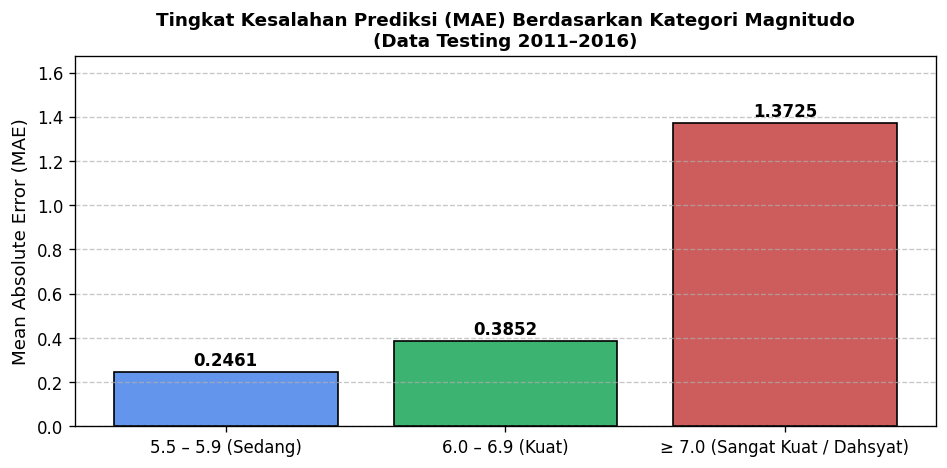

In [87]:
# E.5 Analisis Kesalahan Prediksi Berdasarkan Rentang Magnitudo

bins = [5.5, 6.0, 7.0, 10.0]
labels = ["5.5 – 5.9 (Sedang)", "6.0 – 6.9 (Kuat)", "≥ 7.0 (Sangat Kuat / Dahsyat)"]
df_hasil_test["Kategori Magnitudo"] = pd.cut(df_hasil_test["Magnitude Aktual"], bins=bins, labels=labels, right=False)

ringkasan_kategori = df_hasil_test.groupby("Kategori Magnitudo", observed=False).agg(
    Jumlah_Sampel=("Magnitude Aktual", "count"),
    Rata2_Aktual=("Magnitude Aktual", "mean"),
    Rata2_Prediksi=("Prediksi Ridge", "mean"),
    Rata2_Residual=("Residual", "mean"),
    MAE=("Abs Error", "mean")
).reset_index()

ringkasan_kategori["Proporsi (%)"] = (ringkasan_kategori["Jumlah_Sampel"] / len(df_hasil_test)) * 100

print("===== EVALUASI KESALAHAN PREDIKSI PER KATEGORI MAGNITUDO (DESKRIPTIF) =====")
display(ringkasan_kategori.style.format({
    "Rata2_Aktual": "{:.3f}",
    "Rata2_Prediksi": "{:.3f}",
    "Rata2_Residual": "{:.3f}",
    "MAE": "{:.4f}",
    "Proporsi (%)": "{:.1f}%"
}))

# Visualisasi MAE per Kategori
plt.figure(figsize=(8, 4.0))
bars = plt.bar(ringkasan_kategori["Kategori Magnitudo"], ringkasan_kategori["MAE"], 
               color=["cornflowerblue", "mediumseagreen", "indianred"], edgecolor="black")
plt.ylabel("Mean Absolute Error (MAE)", fontsize=11)
plt.title("Tingkat Kesalahan Prediksi (MAE) Berdasarkan Kategori Magnitudo\n(Data Testing 2011–2016)", fontsize=11, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.7)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03, f"{bar.get_height():.4f}", ha="center", fontsize=10, fontweight="bold")
plt.ylim(0, max(ringkasan_kategori["MAE"]) * 1.22)
plt.tight_layout()
plt.show()

**Interpretasi Analisis Kesalahan per Rentang Magnitudo:**
1. **Kategori Sedang (5,5–5,9):** Model memiliki performa terbaik dengan MAE sebesar **0,2461**. Rata-rata residual adalah **-0,2277**, menunjukkan kecenderungan model memperkirakan sedikit lebih tinggi (*over-predict*) sekitar 0,23 skala magnitudo.
2. **Kategori Kuat (6,0–6,9):** MAE meningkat menjadi **0,3852** dengan rata-rata residual bernilai **+0,3335**, menandakan bahwa model mulai meremehkan (*under-predict*) magnitudo sebenarnya.
3. **Kategori Sangat Kuat / Dahsyat ($\ge 7,0$):** MAE melonjak tinggi menjadi **1,3725** dengan seluruh residual bernilai positif (rata-rata residual = **+1,3725**). Ini menegaskan bahwa untuk gempa berkekuatan dahsyat, model regresi linier secara konsisten mengalami *under-prediction* berat karena kecenderungannya meregresikan estimasi ke arah rata-rata populasi.

---

# BAGIAN F — KONKLUSI (CONCLUSION)

## F.1 Kesimpulan Analisis Data (EDA & Data Understanding)

Berdasarkan eksplorasi data komprehensif pada kejadian gempa bumi signifikan global (1965–2016):
1. **Karakteristik Distribusi Magnitudo:** Seluruh sampel dalam dataset berada pada rentang batas minimum 5,5 hingga maksimum 9,1 dengan nilai rata-rata 5,88. Distribusi magnitudo menunjukkan kemencengan ke kanan (*right-skewed*), di mana sekitar 69% kejadian terpusat pada rentang magnitudo 5,5–5,9.
2. **Karakteristik Kedalaman:** Mayoritas gempa bumi tergolong gempa dangkal (*shallow earthquakes*) dengan kedalaman $< 70$ km (median 33,0 km). Gempa dangkal ini merupakan sumber utama ancaman kerusakan infrastruktur dan keselamatan manusia di daratan.
3. **Sebaran Spasial Geografis:** Visualisasi episentrum membuktikan bahwa aktivitas seismik global terkonsentrasi sangat kuat di sepanjang batas-batas lempeng tektonik utama dunia, terutama zona Cincin Api Pasifik (*Pacific Ring of Fire*).
4. **Hubungan Antarvariabel:** Korelasi linier maupun Spearman antara kedalaman (`Depth`) dan magnitudo (`Magnitude`) bernilai sangat mendekati nol (-0,026), membuktikan secara empiris bahwa kedalaman hiposenter tidak berbanding lurus dengan besaran magnitudo gempa bumi.
5. **Kondisi Missing Value:** Fitur `Depth Seismic Stations` memiliki missing value yang masif pada era historis pra-2000 (mencapai 96,9% pada data training). Imputasi median berbasis data pelatihan berhasil menangani nilai kosong ini secara metodologis tanpa kebocoran data.

## F.2 Kesimpulan Pemodelan

1. **Integritas Metodologi & Pencegahan Data Leakage:** Skema pembagian kronologis (Training: 1965–2000, Validation: 2001–2010, Testing: 2011–2016) dan penerapan pipeline scikit-learn berhasil menjamin bahwa seluruh proses imputasi median dan standardisasi fitur hanya dipelajari dari data pelatihan, mencegah bias informasi masa depan.
2. **Model Terbaik Terpilih:** Pada tahap validasi, model **Ridge Regression ($\alpha=1.0$)** terpilih sebagai model terbaik dengan mengungguli model baseline `DummyRegressor` (MAE 0,2862 vs 0,3123; RMSE 0,3793 vs 0,4240; dan $R^2$ 0,1997 vs -0,0005). Penerapan regularisasi L2 memberikan kestabilan estimasi parameter koefisien yang lebih unggul terhadap multikolinearitas spasial dan temporal.
3. **Fitur Paling Kontributif:** Analisis koefisien regresi menunjukkan bahwa `Year` (bobot -0,0280) dan `Depth Seismic Stations` (bobot +0,0270) menjadi dua prediktor linier paling dominan, merefleksikan pengaruh kepadatan stasiun seismik terhadap pencatatan magnitudo gempa bumi.

## F.3 Interpretasi Hasil Evaluasi Akhir

1. **Akurasi Pengujian Akhir:** Pengujian independen pada data testing (2011–2016, 3.013 sampel kejadian gempa) menghasilkan **MAE sebesar 0,3224**, **RMSE sebesar 0,4413**, dan **$R^2$ sebesar -0,0170**.
2. **Makna Praktis Metrik:** Nilai MAE sebesar 0,3224 menunjukkan bahwa rata-rata deviasi absolut antara nilai estimasi model dengan magnitudo gempa aktual adalah sekitar **0,32 skala magnitudo**. Pada gempa bermagnitudo 5,5 hingga 6,5, akurasi ini cukup memadai untuk estimasi cepat berbasis data katalog awal.
3. **Penurunan Performa Temporal:** Terjadinya penurunan nilai $R^2$ pada periode pengujian modern (2011–2016) mengindikasikan adanya pergeseran distribusi temporal (*covariate shift*). Peningkatan kualitas dan teknologi jaringan stasiun seismik modern menyebabkan pola pencatatan data katalog historis era 1965–2000 mengalami penurunan daya generalisasi linier saat diterapkan pada dekade terbaru.

## F.4 Keterbatasan Penelitian dan Rekomendasi

1. **Batasan Cakupan Data:** Dataset hanya mencakup gempa berkekuatan signifikan ($M \ge 5,5$). Akibatnya, model ini tidak dapat diterapkan untuk memperkirakan aktivitas seismisitas mikro atau gempa kecil di bawah ambang batas tersebut.
2. **Ketiadaan Parameter Geofisika Langsung:** Fitur-fitur katalog yang tersedia (koordinat, waktu, kedalaman, dan stasiun pencatat) belum mencakup parameter fisika rekahan yang sesungguhnya menentukan pelepasan energi gempa bumi, seperti luas bidang gelincir (*rupture area*), pergeseran sesar (*fault displacement*), dan penurunan tegangan batuan (*stress drop*).
3. **Ketidaklengkapan Pencatatan Historis:** Fitur `Depth Seismic Stations` memiliki proporsi nilai hilang yang sangat masif pada era sebelum tahun 2000 (mencapai 96,9% pada data training). Meskipun imputasi median training telah diterapkan secara metodologis, kondisi ini tetap membatasi variasi sinyal yang dapat dipelajari algoritma.
4. **Batasan Etika & Klaim Ilmiah Seismologi:** Proyek ini murni mengembangkan sistem **estimasi retrospektif magnitudo berdasarkan karakteristik kejadian seismik yang telah tercatat**, dan **BUKAN** sistem untuk meramalkan (*predict*) kapan, di mana, atau apakah gempa bumi akan terjadi di masa depan, serta tidak dapat digunakan sebagai sistem peringatan dini gempa bumi (*early warning system*).